# Домашнее задание 1. Свёртки, обучение глубоких сетей, adversarial robustness

**Дедлайн:** ДД.ММ.2026, 23:59 (3 недели).

- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры, cell metadata и открытые тесты сохраняйте; можно добавлять свои ячейки. Открытые тесты проверяют часть контракта, при оценке будут и другие входы в пределах условия.
- После вопроса приведите наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2–4 предложений; для составного вопроса можно ответить по пунктам. Отсутствие ожидаемого эффекта — допустимый результат, если эксперимент корректен и вы это обсудили.
- Разделы 1–4, 5.1 и 6 обязательны. В разделе 5 выберите **одну** задачу: 5.2 targeted или 5.3 transfer (`ATTACK_TRACK`). Обе дают по 2 балла; вторая ветка не добавляет баллы. Бонусы 7.1–7.5 выбираются отдельно через `BONUS_TASKS`; за бонусы суммарно можно получить до 4 баллов из 5 предложенных.
- `FAST_MODE = True` — проверка кода на небольшом бюджете; финальные эксперименты делаются с `False`. Не выбранная ветка и выключенные бонусы автоматически пропускаются, даже если их решения пустые.
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts`, который создаётся перед бонусами. Если сдаёте частичное решение, перечислите нерешённые задачи в ячейке ниже и приложите доступные результаты; ошибки и отсутствие зависимых результатов не скрывайте. Для частичной сдачи успешный Run All и полный каталог artifacts не требуются. Баллы выставляются по отдельным критериям, одна ошибка не обнуляет остальные задачи.
- Для CIFAR-10 рекомендуется CUDA GPU с 8 GB памяти или больше; подойдёт Colab T4. FashionMNIST тоже удобно считать на GPU: adversarial training и серии PGD могут занимать десятки минут и дольше на CPU. Реальное время зависит от устройства; замеряйте его в своих прогонах. Бонусы не входят в основной бюджет.
- Можно пользоваться документацией PyTorch и материалами курса. Нельзя вызывать готовую реализацию того, что просят написать (`torch.optim.AdamW` внутри `MyAdamW`, `nn.BatchNorm2d` внутри `MyBatchNorm2d` и т.п.). Повторно использовать код семинаров можно, указав источник.
- В обучающих моделях используйте библиотечные `nn.Conv2d` и `nn.BatchNorm2d`; собственные слои из разделов 1–2 проверяются отдельно. В `train_cifar` нужен ваш `MyAdamW`.

| раздел | задачи | баллы |
|---|---|---|
| 1. Свёртка изнутри | 1.1 `unfold` · 1.2 backward · 1.3 RF и effective RF | 3.5 |
| 2. Нормализация | 2.1 `BatchNorm2d` · 2.2 Conv–BN fusion | 2 |
| 3. Инициализация и optimizer | 3.1 масштаб активаций · 3.2 `AdamW` · 3.3 cosine schedule | 3 |
| 4. ResNet на CIFAR-10 | 4.1 архитектура · 4.2 обучение · 4.3 plain-20 vs plain-56 | 4.5 |
| 5. Атаки | 5.1 PGD-$L_2$ и **одна** из 5.2 / 5.3 | 3 |
| 6. Adversarial training | 6.1 PGD-AT · 6.2 диагностика · 6.3 input gradients | 4 |
| 7*. Бонусы | 7.1 edge of stability · 7.2 FFT · 7.3 Muon · 7.4 $L_0$ · 7.5 catastrophic overfitting | до +4 |
| итого | | 20 + 4 |

Внутри задачи отдельно оцениваются код, эксперимент и объяснение; разбивка указана у каждого задания. Для вычислительного эксперимента нужны корректный протокол и сохранённые результаты, для объяснения — опора на ваши числа и понимание ограничений. Конкретная accuracy и совпадение с «ожидаемой картинкой» сами по себе не являются критерием балла.

Примерный порядок на три недели: первая — разделы 1–3; вторая — CIFAR-10 и выбранная задача об атаках; третья — adversarial training, анализ результатов и финальный прогон.

**Сведения о сдаче.** Укажите устройство, выбранную ветку, использованные внешние источники и нерешённые задачи (если есть).

- Устройство: Google Colab, GPU NVIDIA T4 (CUDA), PyTorch 2.11.0+cu130. Финальный прогон — Restart & Run All с `FAST_MODE = False`.
- Ветка раздела 5: 5.2 targeted (`ATTACK_TRACK = 'targeted'`).
- Бонусы: 7.1, 7.2, 7.3, 7.4, 7.5.
- Внешние источники: документация PyTorch и статьи, на которые ссылается задание.
- Нерешённые задачи: нет.
- Время основных обучений: ResNet-20 — 345 с, plain-20 — 2.9 мин, plain-56 — 8.9 мин, обычная SmallCNN — 7.8 с, PGD-AT — 48 с.

In [1]:
# При необходимости, в отдельном окружении: %pip install -r requirements.txt
import copy
import itertools
import json
import math
from pathlib import Path
import time
import timeit

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import gradcheck
from torchvision import datasets

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12

print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available:  {torch.cuda.is_available()}')
print(f'MPS available:   {torch.backends.mps.is_available()}')

PyTorch version: 2.11.0+cu130
CUDA available:  True
MPS available:   False


In [2]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    torch.manual_seed(seed)
    np.random.seed(seed)


device = get_device()
set_seed(0)
device

device(type='cuda')

In [3]:
FAST_MODE = False   # True — отладка, False — финальный прогон
DATA_ROOT = './data'
ATTACK_TRACK = 'targeted'   # 'targeted' (5.2) или 'transfer' (5.3)
BONUS_TASKS = {'7.1', '7.2', '7.3', '7.4', '7.5'}        # например {'7.2', '7.4'}; пустое множество отключает все бонусы
assert ATTACK_TRACK in {'targeted', 'transfer'}
assert BONUS_TASKS <= {'7.1', '7.2', '7.3', '7.4', '7.5'}
RUN_TIMES = {}

Общие функции для разделов 4–7: данные лежат одним тензором на `device`, батчи режутся индексами (без `DataLoader` — так быстрее для маленьких картинок).

In [4]:
def iterate_batches(X, Y, batch_size, shuffle=True, transform=None):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for start in range(0, len(X), batch_size):
        b = idx[start:start + batch_size]
        yield (X[b] if transform is None else transform(X[b])), Y[b]


@torch.no_grad()
def predict_logits(model, X, batch_size=1000, transform=None):
    model.eval()
    return torch.cat([model(X[i:i + batch_size] if transform is None else transform(X[i:i + batch_size]))
                      for i in range(0, len(X), batch_size)])


def accuracy(logits, Y):
    return (logits.argmax(dim=1) == Y).float().mean().item()


def n_params(model):
    return sum(p.numel() for p in model.parameters())

---
# 1. Свёртка изнутри

## 1.1 `conv2d` через `unfold` (1 балл)

`F.unfold` (im2col) вырезает все патчи, которые видит ядро, и кладёт каждый патч столбцом:
$$
\mathrm{cols}[b,\, (c, u, v),\, \ell] = x_{\mathrm{pad}}\big[b,\, c,\; s\, i_\ell + d\, u,\; s\, j_\ell + d\, v\big], \qquad
\mathrm{cols} \in \mathbb R^{B \times C_{\text{in}} k_h k_w \times L}, \quad L = H_{\text{out}} W_{\text{out}},
$$
где $(i_\ell, j_\ell)$ — позиция $\ell$-го выхода. После этого свёртка — одно матричное умножение:
$$
y[b, o, \ell] = \sum_{(c, u, v)} W[o, (c, u, v)]\; \mathrm{cols}[b, (c, u, v), \ell] + \mathrm{bias}[o].
$$
С `groups = g` каналы делятся на $g$ групп: строки $\mathrm{cols}$ разбиваются на $g$ блоков по $\frac{C_{\text{in}}}{g} k_h k_w$, веса — на $g$ блоков по $\frac{C_{\text{out}}}{g}$ выходов, и каждая группа умножается только на свой блок.

Реализуйте `conv2d_unfold` для 4D-входа: stride, padding и dilation — целые числа или пары, groups — положительное целое, bias может быть `None`. Строковые padding и complex dtype не требуются. Циклов по батчу, каналам и позициям быть не должно.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [5]:
def pair(v):
    return v if isinstance(v, tuple) else (v, v)


def conv_output_size(size, kernel_size, stride=1, padding=0, dilation=1):
    return (size + 2 * padding - dilation * (kernel_size - 1) - 1) // stride + 1


def conv_output_shape(hw, kernel_size, stride=1, padding=0, dilation=1):
    params = zip(hw, pair(kernel_size), pair(stride), pair(padding), pair(dilation))
    return tuple(conv_output_size(*p) for p in params)

In [6]:
def conv2d_unfold(x, weight, bias=None, stride=1, padding=0, dilation=1, groups=1):
    # x: (B, C_in, H, W), weight: (C_out, C_in / groups, kh, kw) -> (B, C_out, H_out, W_out)
    B, C_in, H, W = x.shape
    C_out, _, kh, kw = weight.shape
    H_out, W_out = conv_output_shape((H, W), (kh, kw), stride, padding, dilation)
    cols = F.unfold(x, (kh, kw), dilation=pair(dilation), padding=pair(padding), stride=pair(stride))
    cols = cols.reshape(B, groups, -1, H_out * W_out)
    w = weight.reshape(groups, C_out // groups, -1)
    out = torch.einsum('gok,bgkl->bgol', w, cols).reshape(B, C_out, H_out, W_out)
    if bias is not None:
        out = out + bias.view(1, -1, 1, 1)
    return out

In [7]:
torch.manual_seed(0)
x = torch.randn(2, 6, 11, 14)
n_checked = 0
for k, s, p, d, g in itertools.product([1, 3, (3, 5)], [1, 2, (2, 1)], [0, 1, (2, 1)], [1, 2], [1, 2, 3, 6]):
    if min(conv_output_shape((11, 14), k, s, p, d)) <= 0:
        continue
    w, b = torch.randn(12, 6 // g, *pair(k)), torch.randn(12)
    ref = F.conv2d(x, w, b, stride=s, padding=p, dilation=d, groups=g)
    assert torch.allclose(conv2d_unfold(x, w, b, s, p, d, g), ref, atol=1e-4), (k, s, p, d, g)
    assert torch.allclose(conv2d_unfold(x, w, None, s, p, d, g), ref - b[None, :, None, None], atol=1e-4)
    n_checked += 1
n_checked

216

**Вопрос.** Во сколько раз `cols` больше входа $x$ при $k = 3, 5, 7$ и `padding = k // 2`? Как стоимость im2col по памяти соотносится с тем, что FFT-свёртка выигрывает именно на больших ядрах?

In [8]:
x = torch.randn(8, 64, 32, 32)
for k in [3, 5, 7]:
    print(f'k = {k}: cols / x = {F.unfold(x, k, padding=k // 2).numel() / x.numel():.1f}')

k = 3: cols / x = 9.0
k = 5: cols / x = 25.0
k = 7: cols / x = 49.0


**Ответ.** `cols / x` $= k^2$: 9, 25 и 49 для $k = 3, 5, 7$ — при `padding = k // 2` и stride 1 $L = HW$, и каждый пиксель копируется в $k^2$ патчей. Память im2col (как и FLOPs прямой свёртки) растёт как $k^2$, а у FFT-свёртки стоимость преобразований и поточечного произведения от размера ядра почти не зависит (ядро дополняется нулями до размера карты). Поэтому на больших ядрах FFT выигрывает и по памяти, и по времени, а на $3 \times 3$ её накладные расходы не окупаются.

## 1.2 Backward свёртки руками (1.5 балла)

Свёртка линейна по входу: $\mathrm{vec}(y) = M\, \mathrm{vec}(x) + b$ с разреженной матрицей $M$, в строках которой стоят веса ядра. Для $g = \partial L / \partial y$:
$$
\frac{\partial L}{\partial x} = M^\top g = \texttt{conv\_transpose2d}(g, W), \qquad
\frac{\partial L}{\partial W}[o, (c,u,v)] = \sum_{b,\ell} g[b, o, \ell]\; \mathrm{cols}[b, (c,u,v), \ell], \qquad
\frac{\partial L}{\partial b}[o] = \sum_{b, i, j} g[b, o, i, j].
$$
При stride $s > 1$ разные $H$ дают одинаковый $H_{\text{out}}$, и `conv_transpose2d` не знает, какой размер восстанавливать: нужную форму выбирает `output_padding`
$$
\mathrm{op}_H = H - \big((H_{\text{out}} - 1)s - 2p + k_h\big).
$$

Допишите `backward` (stride и padding — целые числа, dilation = 1, groups = 1). Проверка — `gradcheck` в float64 на размерах, где `output_padding` не равен нулю.

**Оценивание:** код — 1.2; эксперимент — 0; объяснение — 0.3 балла.

In [9]:
class Conv2dFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, weight, bias, stride, padding):
        ctx.save_for_backward(x, weight)
        ctx.stride, ctx.padding = stride, padding
        return F.conv2d(x, weight, bias, stride=stride, padding=padding)

    @staticmethod
    def backward(ctx, grad_out):
        x, weight = ctx.saved_tensors
        s, p = ctx.stride, ctx.padding
        H, W = x.shape[-2:]
        kh, kw = weight.shape[-2:]
        H_out, W_out = grad_out.shape[-2:]
        op = (H - ((H_out - 1) * s - 2 * p + kh), W - ((W_out - 1) * s - 2 * p + kw))
        grad_x = F.conv_transpose2d(grad_out, weight, stride=s, padding=p, output_padding=op)
        cols = F.unfold(x, (kh, kw), padding=p, stride=s)
        grad_w = torch.einsum('bol,bkl->ok', grad_out.flatten(2), cols).view_as(weight)
        grad_b = grad_out.sum(dim=(0, 2, 3)) if ctx.needs_input_grad[2] else None
        return grad_x, grad_w, grad_b, None, None

In [10]:
torch.manual_seed(0)
n_checked = 0
for s, p, (H, W) in itertools.product([1, 2, 3], [0, 1, 2], [(7, 7), (8, 9), (10, 6)]):
    x = torch.randn(2, 3, H, W, dtype=torch.float64, requires_grad=True)
    w = torch.randn(4, 3, 3, 3, dtype=torch.float64, requires_grad=True)
    b = torch.randn(4, dtype=torch.float64, requires_grad=True)
    assert gradcheck(lambda x, w, b: Conv2dFunction.apply(x, w, b, s, p), (x, w, b)), (s, p, H, W)
    n_checked += 1
n_checked

27

**Вопрос.** Приведите два размера $H$, для которых свёртка $3 \times 3$ со stride 2 и padding 1 даёт одинаковый $H_{\text{out}}$, и `output_padding` для каждого.

**Ответ.** Для $k = 3$, $s = 2$, $p = 1$: $H_{\text{out}} = \lfloor (H - 1) / 2 \rfloor + 1$. $H = 7$ и $H = 8$ дают $H_{\text{out}} = 4$, при этом $(H_{\text{out}} - 1)s - 2p + k = 7$, так что $\mathrm{op}_H = 0$ для $H = 7$ и $\mathrm{op}_H = 1$ для $H = 8$.

## 1.3 Receptive field через autograd (1 балл)

Теоретический receptive field (RF) нейрона — область входа, потенциально влияющая на него по архитектуре. Носитель градиента на конкретном входе может быть меньше из-за ReLU, MaxPool или взаимных сокращений. Размер bounding box теоретического RF вдали от границ даёт рекурсия (функция `receptive_field` ниже) по слоям с ядром $k_l$, stride $s_l$ и dilation $d_l$:
$$
k_l^{\mathrm{eff}} = 1 + d_l (k_l - 1), \qquad r_0 = j_0 = 1, \qquad r_l = r_{l-1} + (k_l^{\mathrm{eff}} - 1)\, j_{l-1}, \qquad j_l = j_{l-1}\, s_l,
$$
$j_l$ — расстояние между соседними нейронами слоя $l$ в пикселях входа. Pooling считается так же.

Сети для проверки — свёртки с усредняющими ядрами (все веса $1/k^2$, bias 0) и `AvgPool`, без нелинейностей.

Реализуйте `empirical_rf`: по градиенту суммы каналов центрального выхода по входу найти размер bounding box ненулевых пикселей по высоте и ширине.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [11]:
def receptive_field(layers):
    # layers: список dict(k, s=1, d=1); возвращает (r, j) после каждого слоя
    r, j = 1, 1
    history = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        r = r + (1 + d * (k - 1) - 1) * j
        j = j * s
        history.append((r, j))
    return history


def make_avg_net(layers, max_pool=False):
    modules = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        if layer.get('pool'):
            modules.append(nn.MaxPool2d(k, s) if max_pool else nn.AvgPool2d(k, s))
        else:
            conv = nn.Conv2d(1, 1, k, stride=s, dilation=d)
            nn.init.constant_(conv.weight, 1 / k ** 2)
            nn.init.zeros_(conv.bias)
            modules.append(conv)
    return nn.Sequential(*modules)


RF_ARCHS = {
    'conv3x3 x4': [dict(k=3)] * 4,
    'conv-pool':  [dict(k=3), dict(k=2, s=2, pool=True), dict(k=3), dict(k=2, s=2, pool=True), dict(k=3)],
    'strided':    [dict(k=5, s=2), dict(k=3, s=2), dict(k=3)],
    'dilated':    [dict(k=3, d=1), dict(k=3, d=2), dict(k=3, d=4)],
}

In [12]:
def empirical_rf(model, in_channels=1, size=96):
    # -> (высота, ширина) bounding box пикселей входа, влияющих на центральный выход
    x = torch.randn(1, in_channels, size, size, requires_grad=True)
    y = model(x)
    h, w = y.shape[-2:]
    grad, = torch.autograd.grad(y[0, :, h // 2, w // 2].sum(), x)
    nz = grad[0].abs().sum(0).nonzero()
    return tuple((nz.max(0).values - nz.min(0).values + 1).tolist())

In [13]:
torch.manual_seed(0)
for name, layers in RF_ARCHS.items():
    r = receptive_field(layers)[-1][0]
    assert empirical_rf(make_avg_net(layers)) == (r, r), name
    print(f'{name:<12} r = {r:>3}   MaxPool instead of AvgPool: {empirical_rf(make_avg_net(layers, max_pool=True))}')

conv3x3 x4   r =   9   MaxPool instead of AvgPool: (9, 9)
conv-pool    r =  18   MaxPool instead of AvgPool: (18, 18)
strided      r =  17   MaxPool instead of AvgPool: (17, 17)
dilated      r =  15   MaxPool instead of AvgPool: (15, 15)


**Вопрос.** Почему для проверки взяты усредняющие ядра без нелинейностей? Что меняется с `MaxPool` и почему?

**Ответ.** Сеть из усредняющих ядер без нелинейностей линейна, и все её коэффициенты положительны: градиент центрального выхода не зависит от входа и строго положителен на всём теоретическом RF — нет ни нулей от ReLU, ни взаимных сокращений, поэтому bounding box обязан совпасть с $r$, и проверка точная. MaxPool пропускает градиент только через argmax каждого окна, так что носитель градиента зависит от входа и может стать меньше и «дырявым». В нашем прогоне bounding box при этом не изменился — (9, 9), (18, 18), (17, 17), (15, 15): pooling есть только в `conv-pool`, а там свёртки $3 \times 3$ до и после pooling размазывают градиент от выбранных позиций до границ RF; уменьшиться может разреженность внутри рамки, а не сама рамка.

### Effective receptive field

Для рассматриваемых усредняющих сетей носитель градиента совпадает с теоретическим RF, но вклад пикселей неравномерный. Для стопки из $L$ усредняющих свёрток $3 \times 3$ карта $\partial y_{\text{center}} / \partial x$ — это $L$-кратная свёртка равномерного ядра, то есть распределение суммы $L$ независимых равномерных величин на $\{-1, 0, 1\}$ по каждой оси:
$$
\sigma_{\text{ERF}} = \sqrt{L \cdot \tfrac23}, \qquad r_L = 2L + 1.
$$
По ЦПТ профиль близок к гауссовскому, и эффективная ширина растёт как $\sqrt L$: [Understanding the Effective Receptive Field in Deep Convolutional Neural Networks](https://arxiv.org/pdf/1701.04128), Luo et al., 2016.

Реализуйте `erf_std`: $|\nabla_x y_{\text{center}}|$, усреднённый по `n_inputs` случайным входам и просуммированный по каналам, нормировать в распределение по строкам и вернуть его стандартное отклонение (в пикселях).

In [14]:
def erf_std(model, in_channels=1, size=96, n_inputs=1):
    x = torch.randn(n_inputs, in_channels, size, size, requires_grad=True)
    y = model(x)
    h, w = y.shape[-2:]
    grad, = torch.autograd.grad(y[:, :, h // 2, w // 2].sum(), x)
    p = grad.abs().mean(0).sum(0).sum(1)
    p = p / p.sum()
    rows = torch.arange(size, dtype=p.dtype)
    mean = (p * rows).sum()
    return (p * (rows - mean) ** 2).sum().sqrt().item()

In [15]:
for L in [1, 2, 4, 8, 16]:
    assert abs(erf_std(make_avg_net([dict(k=3)] * L)) - math.sqrt(2 * L / 3)) < 1e-3, L

Теперь обычная сеть: $L$ свёрток $3 \times 3$ по 16 каналов, ReLU, веса из $\mathcal N(0,\, 2 / \text{fan\_in})$, среднее по 16 входам.

In [16]:
def make_relu_net(L, width=16, seed=0):
    torch.manual_seed(seed)
    layers, c = [], 1
    for _ in range(L):
        conv = nn.Conv2d(c, width, 3)
        nn.init.kaiming_normal_(conv.weight, nonlinearity='relu')
        nn.init.zeros_(conv.bias)
        layers += [conv, nn.ReLU()]
        c = width
    return nn.Sequential(*layers)


depths = [1, 2, 4, 8, 16]
erf = {'theoretical RF / 2': [float(L) for L in depths],
       'ERF std, averaging kernels': [erf_std(make_avg_net([dict(k=3)] * L)) for L in depths],
       'ERF std, random ReLU net': [erf_std(make_relu_net(L), n_inputs=16) for L in depths]}
for name, values in erf.items():
    print(f'{name:<28}' + ''.join(f'{v:>7.2f}' for v in values))

theoretical RF / 2             1.00   2.00   4.00   8.00  16.00
ERF std, averaging kernels     0.82   1.15   1.63   2.31   3.27
ERF std, random ReLU net       0.79   1.29   1.97   3.08   4.44


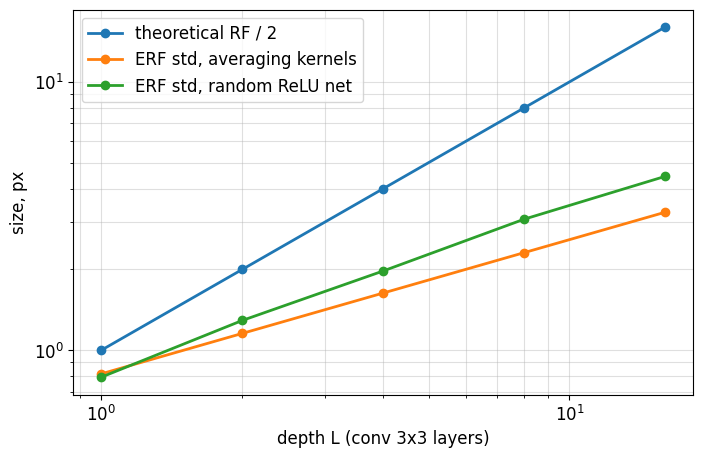

In [17]:
plt.figure(figsize=(8, 5))
for name, values in erf.items():
    plt.loglog(depths, values, 'o-', linewidth=2, label=name)
plt.xlabel('depth L (conv 3x3 layers)')
plt.ylabel('size, px')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Как отношение эффективного RF к теоретическому меняется с глубиной (наклоны на log-log графике)? Как ведёт себя сеть с ReLU по сравнению с усредняющей?

**Ответ.** Теоретический RF растёт линейно (наклон 1 на log-log), а ERF std у усредняющей сети — как $\sqrt L$: от 0.82 при $L = 1$ до 3.27 при $L = 16$ (рост в 4 раза при росте глубины в 16 раз, наклон 0.5, совпадает с $\sqrt{2L/3}$). Поэтому отношение эффективного RF к теоретическому падает как $1/\sqrt L$: 0.82 при $L = 1$ и $3.27 / 16 \approx 0.20$ при $L = 16$. Сеть с ReLU и случайными весами ведёт себя похоже, но растёт чуть быстрее: от 0.79 до 4.44, наклон $\approx 0.62$, так что на глубине 16 её ERF шире усредняющей (4.44 против 3.27), но всё равно заметно уже теоретического RF. Вывод по одной инициализации и 16 входам, без обучения.

---
# 2. Нормализация

## 2.1 `BatchNorm2d` с нуля (1 балл)

В `train()`: статистики текущего батча по каналу (среднее по $b, h, w$), нормировка смещённой дисперсией и обновление буферов
$$
\hat\mu \leftarrow (1 - m)\,\hat\mu + m\, \mu_{\text{batch}}, \qquad
\hat\sigma^2 \leftarrow (1 - m)\,\hat\sigma^2 + m\, \frac{n}{n - 1}\, \sigma^2_{\text{batch}}, \qquad n = BHW,
$$
в running-дисперсию идёт несмещённая оценка. В `eval()` — нормировка по $\hat\mu, \hat\sigma^2$. Параметры `weight` ($\gamma$) и `bias` ($\beta$), буферы `running_mean`, `running_var`, `num_batches_tracked` — с теми же именами, что в `nn.BatchNorm2d`, чтобы `load_state_dict` был совместим.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [18]:
class MyBatchNorm2d(nn.Module):
    def __init__(self, num_features, eps=1e-5, momentum=0.1):
        super().__init__()
        self.eps, self.momentum = eps, momentum
        self.weight = nn.Parameter(torch.ones(num_features))
        self.bias = nn.Parameter(torch.zeros(num_features))
        self.register_buffer('running_mean', torch.zeros(num_features))
        self.register_buffer('running_var', torch.ones(num_features))
        self.register_buffer('num_batches_tracked', torch.tensor(0, dtype=torch.long))

    def forward(self, x):
        if self.training:
            mean = x.mean(dim=(0, 2, 3))
            var = x.var(dim=(0, 2, 3), correction=0)
            n = x.numel() // x.shape[1]
            with torch.no_grad():
                self.running_mean.mul_(1 - self.momentum).add_(self.momentum * mean)
                self.running_var.mul_(1 - self.momentum).add_(self.momentum * var * n / (n - 1))
                self.num_batches_tracked += 1
        else:
            mean, var = self.running_mean, self.running_var
        x_hat = (x - mean[None, :, None, None]) / torch.sqrt(var[None, :, None, None] + self.eps)
        return x_hat * self.weight[None, :, None, None] + self.bias[None, :, None, None]

In [19]:
torch.manual_seed(0)
mine, ref = MyBatchNorm2d(8), nn.BatchNorm2d(8)
assert set(dict(mine.named_parameters())) == {'weight', 'bias'}
assert set(dict(mine.named_buffers())) == {'running_mean', 'running_var', 'num_batches_tracked'}
with torch.no_grad():
    for m in (mine, ref):
        m.weight.copy_(torch.linspace(0.5, 2, 8))
        m.bias.copy_(torch.linspace(-1, 1, 8))

for step in range(10):
    x = (torch.randn(4, 8, 5, 5) * 3 + 2).requires_grad_(True)
    out_mine, out_ref = mine(x), ref(x)
    assert torch.allclose(out_mine, out_ref, atol=1e-5), step
    g = torch.randn_like(out_ref)
    grads_mine = torch.autograd.grad(out_mine, (x, mine.weight, mine.bias), g)
    grads_ref = torch.autograd.grad(out_ref, (x, ref.weight, ref.bias), g)
    assert all(torch.allclose(a, b, atol=1e-4) for a, b in zip(grads_mine, grads_ref)), step

for name, buf in ref.named_buffers():
    assert torch.allclose(getattr(mine, name).float(), buf.float(), atol=1e-5), name

mine.eval(), ref.eval()
x = torch.randn(4, 8, 5, 5)
assert torch.allclose(mine(x), ref(x), atol=1e-5)
mine.load_state_dict(ref.state_dict())

<All keys matched successfully>

**Вопрос.** Почему в running-дисперсию идёт несмещённая оценка, а в нормировку батча — смещённая? Насколько они различаются при $B = 4$ и карте $5 \times 5$, и при $B = 2$ и карте $1 \times 1$?

**Ответ.** В `train()` нужно нормировать именно текущие $n = BHW$ чисел, чтобы у них было ровно нулевое среднее и единичная дисперсия, — это точная статистика батча, а не оценка, поэтому берётся смещённая $\sigma^2_{\text{batch}}$. Running-дисперсия используется на инференсе как оценка дисперсии по всему распределению данных, а несмещённая оценка генеральной дисперсии по выборке из $n$ значений требует поправки $\frac{n}{n-1}$. Различие — ровно этот множитель: при $B = 4$, $5 \times 5$ $n = 100$ и $\frac{n}{n-1} \approx 1.0101$ (≈1%), при $B = 2$, $1 \times 1$ $n = 2$ — в 2 раза.

## 2.2 Слияние свёртки и BatchNorm для инференса (1 балл)

В `eval()` BN — поканальное аффинное преобразование с фиксированными $\hat\mu, \hat\sigma^2$, поэтому $\mathrm{BN}(\mathrm{conv}(x))$ — снова свёртка с другими весами $W'$ и bias $b'$.

1. Выведите $W'$ и $b'$ в ячейке «Ответ» ниже.
2. Реализуйте `fuse_conv_bn(conv, bn)`, возвращающую новую `nn.Conv2d`: сохраняются `dtype`, `device`, `padding_mode`, `groups`, stride, padding и dilation; bias у исходной свёртки может отсутствовать. Входные модули в `eval()`, BN с affine и running statistics; исходные веса не менять.
3. Реализуйте `fuse_sequential(seq)` для плоского `nn.Sequential` в `eval()`: каждую соседнюю пару `Conv2d, BatchNorm2d` заменить свёрткой. Остальные модули скопировать через `copy.deepcopy`, исходную сеть не менять; рекурсивный обход вложенных контейнеров не требуется.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

**Ответ.** В `eval()` для канала $o$: $\mathrm{BN}(z)_o = \gamma_o \dfrac{z_o - \hat\mu_o}{\sqrt{\hat\sigma^2_o + \epsilon}} + \beta_o$. Обозначим $a_o = \gamma_o / \sqrt{\hat\sigma^2_o + \epsilon}$ и подставим $z_o = (W * x)_o + b_o$:
$$
W'_o = a_o\, W_o, \qquad b'_o = a_o\,(b_o - \hat\mu_o) + \beta_o,
$$
где $W_o$ — все веса выходного канала $o$ (форма $C_{\text{in}}/g \times k_h \times k_w$), а при отсутствии bias $b_o = 0$. Умножение ядра на константу коммутирует со свёрткой, поэтому stride, padding, dilation, groups и `padding_mode` не меняются.

In [20]:
@torch.no_grad()
def fuse_conv_bn(conv, bn):
    fused = nn.Conv2d(conv.in_channels, conv.out_channels, conv.kernel_size, stride=conv.stride,
                      padding=conv.padding, dilation=conv.dilation, groups=conv.groups, bias=True,
                      padding_mode=conv.padding_mode, device=conv.weight.device, dtype=conv.weight.dtype)
    scale = bn.weight / torch.sqrt(bn.running_var + bn.eps)
    b = conv.bias if conv.bias is not None else torch.zeros_like(bn.running_mean)
    fused.weight.copy_(conv.weight * scale[:, None, None, None])
    fused.bias.copy_((b - bn.running_mean) * scale + bn.bias)
    return fused


def fuse_sequential(seq):
    mods, out, i = list(seq), [], 0
    while i < len(mods):
        if i + 1 < len(mods) and isinstance(mods[i], nn.Conv2d) and isinstance(mods[i + 1], nn.BatchNorm2d):
            out.append(fuse_conv_bn(mods[i], mods[i + 1]))
            i += 2
        else:
            out.append(copy.deepcopy(mods[i]))
            i += 1
    return nn.Sequential(*out)

In [21]:
torch.manual_seed(0)
for cfg in [dict(bias=True), dict(bias=False), dict(groups=4), dict(stride=2, padding=1, dilation=2)]:
    conv, bn = nn.Conv2d(8, 16, 3, **cfg), nn.BatchNorm2d(16)
    with torch.no_grad():
        bn.weight.uniform_(0.5, 2)
        bn.bias.uniform_(-1, 1)
        for _ in range(5):
            bn(conv(torch.randn(8, 8, 12, 12) * 2 + 1))   # накопить running-статистики
    conv.eval(), bn.eval()
    x = torch.randn(4, 8, 12, 12)
    fused = fuse_conv_bn(conv, bn)
    assert isinstance(fused, nn.Conv2d)
    assert torch.allclose(fused(x), bn(conv(x)), atol=1e-5), cfg

conv = nn.Conv2d(4, 8, 3, padding=1, padding_mode='reflect', groups=2, bias=False).double().eval()
bn = nn.BatchNorm2d(8).double().eval()
x = torch.randn(2, 4, 9, 11, dtype=torch.float64)
fused = fuse_conv_bn(conv, bn)
assert fused.weight.dtype == x.dtype and fused.padding_mode == 'reflect'
assert torch.allclose(fused(x), bn(conv(x)), atol=1e-10, rtol=1e-10)

In [22]:
def make_vgg_like(width=64, n_blocks=6):
    layers, c = [], 3
    for i in range(n_blocks):
        layers += [nn.Conv2d(c, width, 3, padding=1, bias=False), nn.BatchNorm2d(width), nn.ReLU()]
        c = width
        if i % 2 == 1:
            layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(width, 10))


torch.manual_seed(0)
vgg = make_vgg_like()
with torch.no_grad():
    for _ in range(5):
        vgg(torch.randn(32, 3, 32, 32))   # train-режим: копим статистики
vgg.eval()
vgg_fused = fuse_sequential(vgg).eval()
x = torch.randn(64, 3, 32, 32)
assert not any(isinstance(m, nn.BatchNorm2d) for m in vgg_fused.modules())
assert torch.allclose(vgg(x), vgg_fused(x), atol=1e-4)

In [23]:
with torch.inference_mode():
    t_bn = min(timeit.repeat(lambda: vgg(x), number=5, repeat=5)) / 5
    t_fused = min(timeit.repeat(lambda: vgg_fused(x), number=5, repeat=5)) / 5
print(f'Conv + BN: {t_bn * 1000:.1f} ms   fused: {t_fused * 1000:.1f} ms   speedup {t_bn / t_fused:.2f}x')

Conv + BN: 126.6 ms   fused: 146.7 ms   speedup 0.86x


**Вопрос.** Почему слияние корректно только в `eval()`? Что даёт слияние и от чего зависит выигрыш?

**Ответ.** В `train()` BN нормирует по статистикам текущего батча, которые меняются от батча к батчу и зависят от других объектов, и ещё обновляет running-буферы — это не фиксированное аффинное преобразование, поэтому заменить его постоянными $W', b'$ можно только в `eval()`. Слияние убирает отдельный проход BN по тензору активаций (чтение и запись памяти и запуск лишнего kernel). В нашем замере выигрыша нет: 126.6 мс против 146.7 мс, speedup 0.86x — на CPU Colab с маленьким VGG эффект меньше шума измерения (BN в eval — дешёвая поэлементная операция рядом с дорогой свёрткой $3 \times 3$ на 64 канала). Выигрыш зависит от доли memory-bound операций в общем времени, устройства и backend (сливает ли он операции сам), размера батча и ширины слоёв.

---
# 3. Инициализация и оптимизатор

## 3.1 Дисперсия активаций по глубине (1 балл)

Слой $h = W z$, $W_{ij}$ независимы, $\mathbb E W_{ij} = 0$, $\mathrm{Var}\, W_{ij} = v$, $W$ не зависит от $z \in \mathbb R^{n}$:
$$
\mathrm{Var}(h_i) = n\, v\; \mathbb E\big[z_j^2\big].
$$

1. В ячейке «Ответ» ниже выведите $v$, при котором $\mathrm{Var}(h)$ не меняется от слоя к слою, для $z = \mathrm{ReLU}(h^{\text{prev}})$ с симметричным $h^{\text{prev}}$ и для $\tanh$ в линейном режиме. Инициализация `nn.Linear` по умолчанию — $\mathcal U(-1/\sqrt n,\, 1/\sqrt n)$: во сколько раз за слой меняется стандартное отклонение активаций для ReLU?
2. Реализуйте `activation_stds`: MLP глубины 50 и ширины 256 без bias, на входе $\mathcal N(0, I)$, вернуть `h.std().item()` после каждой активации — по **всем** элементам тензора `(n, width)`, а не среднее std по отдельным нейронам. Верните список из `depth` чисел.

**Оценивание:** код — 0.3; эксперимент — 0.3; объяснение — 0.4 балла.

**Ответ.** Для ReLU при симметричном $h^{\text{prev}}$: $\mathbb E z^2 = \frac12 \mathrm{Var}(h^{\text{prev}})$, откуда $\mathrm{Var}(h) = \frac{n v}{2} \mathrm{Var}(h^{\text{prev}})$ и $v = 2/n$ (Kaiming). Для $\tanh$ в линейном режиме $\tanh h \approx h$, $\mathbb E z^2 = \mathrm{Var}(h^{\text{prev}})$ и $v = 1/n$ (Xavier: $2/(n_{\text{in}} + n_{\text{out}}) = 1/n$). Для $\mathcal U(-1/\sqrt n, 1/\sqrt n)$ $v = \frac{(2/\sqrt n)^2}{12} = \frac{1}{3n}$, и с ReLU дисперсия за слой умножается на $n \cdot \frac{1}{3n} \cdot \frac12 = \frac16$, то есть std — на $1/\sqrt 6 \approx 0.41$ (за 50 слоёв ≈ $10^{-19.5}$).

In [24]:
INITS = {
    'N(0, 0.01^2)':    lambda w: nn.init.normal_(w, std=0.01),
    'PyTorch default': lambda w: nn.init.kaiming_uniform_(w, a=math.sqrt(5)),
    'Xavier':          nn.init.xavier_normal_,
    'Kaiming':         lambda w: nn.init.kaiming_normal_(w, nonlinearity='relu'),
}


def activation_stds(init, act, depth=50, width=256, n=1024, seed=0):
    torch.manual_seed(seed)
    h = torch.randn(n, width)
    stds = []
    for _ in range(depth):
        w = torch.empty(width, width)
        init(w)
        h = act(h @ w.T)
        stds.append(h.std().item())
    return stds

In [25]:
stds = {(name, act_name): activation_stds(init, act)
        for name, init in INITS.items() for act_name, act in [('tanh', torch.tanh), ('ReLU', torch.relu)]}

kaiming_relu = stds['Kaiming', 'ReLU']
assert len(kaiming_relu) == 50 and np.isfinite(kaiming_relu).all()
print(f'Kaiming + ReLU, last / first std: {kaiming_relu[-1] / kaiming_relu[0]:.3f}')
default_relu = np.array(stds['PyTorch default', 'ReLU'])
rate = np.exp(np.mean(np.diff(np.log(default_relu))))   # средний множитель std за слой
assert abs(rate - 1 / math.sqrt(6)) < 0.03
rate

Kaiming + ReLU, last / first std: 0.758


np.float64(0.40910241812972786)

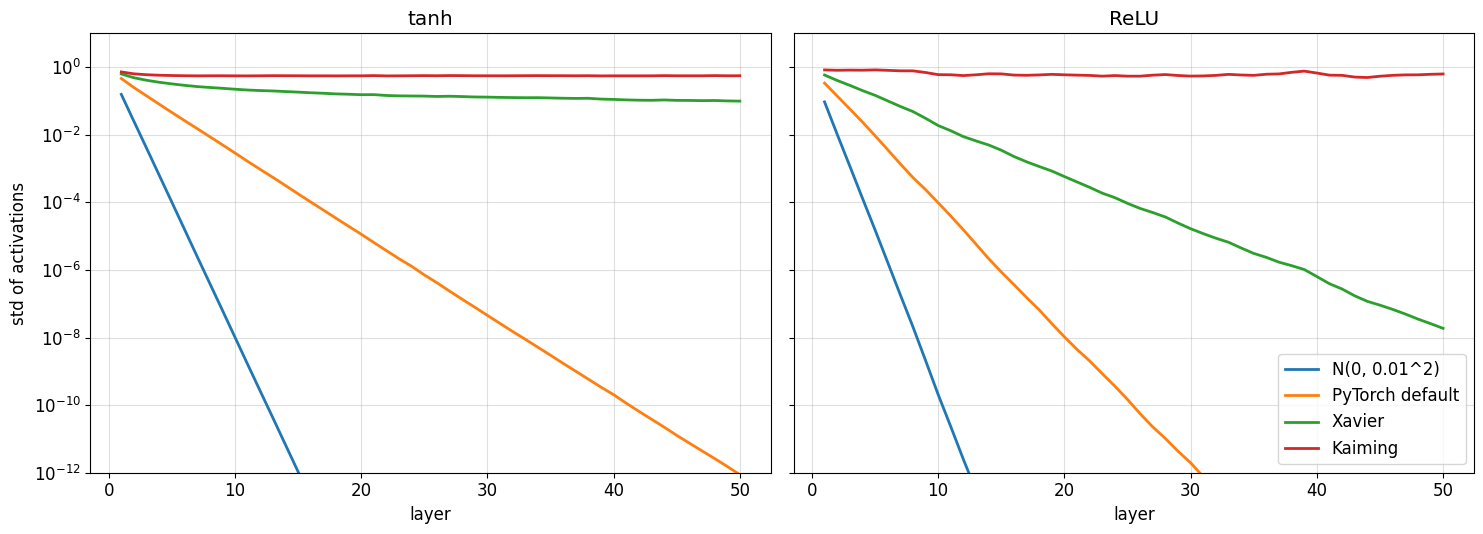

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, act_name in zip(axes, ['tanh', 'ReLU']):
    for name in INITS:
        ax.semilogy(range(1, 51), stds[name, act_name], linewidth=2, label=name)
    ax.set_title(act_name)
    ax.set_xlabel('layer')
    ax.grid(True, which='both', alpha=0.4)
axes[0].set_ylabel('std of activations')
axes[0].set_ylim(1e-12, 10)
axes[1].legend()
plt.tight_layout()
plt.show()

**Вопрос.** Какие пары (инициализация, активация) сохраняют масштаб на 50 слоях? Почему сети с инициализацией PyTorch по умолчанию всё равно обучаются (например, ResNet в задаче 4.2)?

**Ответ.** Масштаб на 50 слоях сохраняют Kaiming + ReLU (отношение последнего std к первому 0.758) и Kaiming + tanh (tanh ограничен и не даёт расти), а Xavier + tanh медленно, не экспоненциально, спадает примерно до 0.1. Остальные пары затухают экспоненциально: PyTorch default — в $\approx 0.409 \approx 1/\sqrt6$ раз за слой с ReLU и в $\approx 1/\sqrt3$ с tanh (до $10^{-12}$ к 30–50 слою), Xavier + ReLU — в $1/\sqrt2$ за слой (≈ $10^{-8}$ к 50 слою), $\mathcal N(0, 0.01^2)$ — быстрее всех. ResNet с инициализацией по умолчанию всё равно обучается: после каждой свёртки стоит BatchNorm, который возвращает активации к единичному масштабу независимо от масштаба весов, а residual-связи дают тождественный путь сигналу и градиенту через всю глубину.

## 3.2 `AdamW` своими руками (1.5 балла)

Шаг $t = 1, 2, \dots$; $\eta$ — learning rate, $\lambda$ — weight decay, $g_t$ — градиент:
$$
\theta \leftarrow \theta - \eta\lambda\,\theta, \qquad
m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t, \qquad
v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2,
$$
$$
\hat m_t = \frac{m_t}{1 - \beta_1^t}, \qquad \hat v_t = \frac{v_t}{1 - \beta_2^t}, \qquad
\theta \leftarrow \theta - \eta\, \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}.
$$
Флаг `bias_correction=False` выключает деление на $1 - \beta^t$. Гиперпараметры берутся из `group` — у разных групп параметров они могут отличаться (в `train_cifar` из задачи 4.2 weight decay не применяется к параметрам BN и bias).

**Оценивание:** код — 1.1; эксперимент — 0.1; объяснение — 0.3 балла.

In [27]:
class MyAdamW(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2, bias_correction=True):
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay, bias_correction=bias_correction)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            beta1, beta2 = group['betas']
            for p in group['params']:
                if p.grad is None:
                    continue
                state = self.state[p]
                if not state:
                    state['step'] = 0
                    state['exp_avg'] = torch.zeros_like(p)
                    state['exp_avg_sq'] = torch.zeros_like(p)
                state['step'] += 1
                t, m, v = state['step'], state['exp_avg'], state['exp_avg_sq']
                p.mul_(1 - group['lr'] * group['weight_decay'])
                m.mul_(beta1).add_(p.grad, alpha=1 - beta1)
                v.mul_(beta2).addcmul_(p.grad, p.grad, value=1 - beta2)
                if group['bias_correction']:
                    m_hat, v_hat = m / (1 - beta1 ** t), v / (1 - beta2 ** t)
                else:
                    m_hat, v_hat = m, v
                p.sub_(group['lr'] * m_hat / (v_hat.sqrt() + group['eps']))

In [28]:
def final_params(make_optimizer, steps=100):
    torch.manual_seed(0)
    model = nn.Sequential(nn.Linear(10, 32), nn.Tanh(), nn.Linear(32, 1))
    optimizer = make_optimizer(model)
    gen = torch.Generator().manual_seed(1)
    for _ in range(steps):
        x = torch.randn(64, 10, generator=gen)
        loss = F.mse_loss(model(x), x[:, :1] ** 2)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return torch.cat([p.detach().flatten() for p in model.parameters()])


def param_groups(model, wd):
    return [dict(params=[p for p in model.parameters() if p.ndim > 1], weight_decay=wd),
            dict(params=[p for p in model.parameters() if p.ndim <= 1], weight_decay=0.0, lr=3e-3)]


for kwargs in [dict(lr=1e-2), dict(lr=1e-2, weight_decay=0.1), dict(lr=3e-3, betas=(0.8, 0.9), eps=1e-1)]:
    mine = final_params(lambda m: MyAdamW(m.parameters(), **kwargs))
    ref = final_params(lambda m: torch.optim.AdamW(m.parameters(), **kwargs))
    assert torch.allclose(mine, ref, atol=1e-5), kwargs
mine = final_params(lambda m: MyAdamW(param_groups(m, 0.1), lr=1e-2))
ref = final_params(lambda m: torch.optim.AdamW(param_groups(m, 0.1), lr=1e-2))
assert torch.allclose(mine, ref, atol=1e-5)

Длина шага при постоянном градиенте $g = 1$:

In [29]:
def step_lengths(make_optimizer, steps=1000):
    p = torch.zeros(1, requires_grad=True)
    optimizer = make_optimizer([p])
    lengths = []
    for _ in range(steps):
        before = p.item()
        optimizer.zero_grad()
        p.sum().backward()
        optimizer.step()
        lengths.append(before - p.item())
    return np.array(lengths)


lr = 0.01
bc_runs = {bc: step_lengths(lambda ps: MyAdamW(ps, lr=lr, weight_decay=0, bias_correction=bc)) for bc in [True, False]}
for bc, lengths in bc_runs.items():
    ratio = np.round(lengths / lr, 4)
    print(f'bias_correction={bc!s:<5}  step / lr: ' + '  '.join(f't={t}: {ratio[t - 1]:.2f}' for t in [1, 10, 100, 1000])
          + f'   max {ratio.max():.2f} at t={ratio.argmax() + 1}')

bias_correction=True   step / lr: t=1: 1.00  t=10: 1.00  t=100: 1.00  t=1000: 1.00   max 1.00 at t=1
bias_correction=False  step / lr: t=1: 3.16  t=10: 6.53  t=100: 3.24  t=1000: 1.26   max 6.57 at t=12


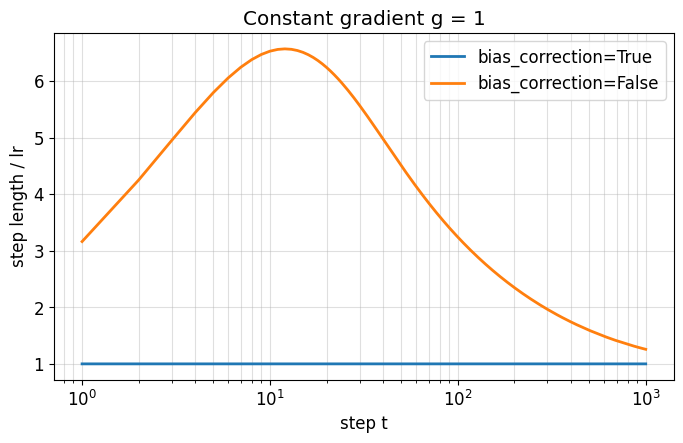

In [30]:
plt.figure(figsize=(8, 4.5))
for bc, lengths in bc_runs.items():
    plt.semilogx(range(1, len(lengths) + 1), lengths / lr, linewidth=2, label=f'bias_correction={bc}')
plt.xlabel('step t')
plt.ylabel('step length / lr')
plt.title('Constant gradient g = 1')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Выведите длину шага без bias correction при $g_t \equiv 1$ как функцию $t$ и сравните с выводом ячейки. Чем это опасно в начале обучения?

**Ответ.** Без bias correction при $g_t \equiv 1$: $m_t = 1 - \beta_1^t$, $v_t = 1 - \beta_2^t$, длина шага
$$
\Delta_t = \eta\, \frac{1 - \beta_1^t}{\sqrt{1 - \beta_2^t} + \epsilon}.
$$
При $\beta = (0.9, 0.999)$: $\Delta_1 / \eta \approx 3.16$, $\Delta_{10} / \eta \approx 6.53$, $\Delta_{100} / \eta \approx 3.24$, $\Delta_{1000} / \eta \approx 1.26$, максимум $\approx 6.57$ при $t = 12$; к $\eta$ шаг приходит лишь при $t \gg 1/(1 - \beta_2) = 1000$. С bias correction шаг равен $\eta$ с первого же шага. Опасность: знаменатель $\sqrt{v_t}$ «прогревается» на порядок медленнее числителя, и первые сотни шагов эффективный lr в 3–6.5 раз больше заданного — ровно тогда, когда веса случайные, градиенты большие и loss наиболее «острый», что грозит расхождением или неудачным ранним режимом обучения.

## 3.3 Cosine schedule (0.5 балла)

Множитель learning rate для `LambdaLR` (шаг $t$ считается с нуля, $T$ — число шагов, $r$ — доля от начального lr в конце):
$$
\lambda(t) = r + (1 - r)\, \frac{1 + \cos\big(\pi \min(1,\, t / T)\big)}{2}.
$$
На интервале от нулевого шага до $T$ это то же расписание, что `CosineAnnealingLR(T_max=T, eta_min=r·lr)`; после $T$ наша функция остаётся на минимуме, в отличие от продолжения cosine в PyTorch; проверка — совпадение learning rate по шагам с вашим `MyAdamW`.

**Оценивание:** код — 0.3; эксперимент — 0; объяснение — 0.2 балла.

In [31]:
def cosine_lr(step, total_steps, min_ratio=0.0):
    return min_ratio + (1 - min_ratio) * (1 + math.cos(math.pi * min(1.0, step / total_steps))) / 2

In [32]:
T, r, base_lr = 500, 0.1, 3e-3
lam = [cosine_lr(t, T, r) for t in range(T + 1)]
assert abs(lam[0] - 1) < 1e-12 and abs(lam[T] - r) < 1e-12 and abs(cosine_lr(2 * T, T, r) - r) < 1e-12
assert abs(lam[T // 2] - (r + (1 - r) / 2)) < 1e-9


def lr_trace(make_scheduler, steps=T):
    p = torch.zeros(1, requires_grad=True)
    optimizer = MyAdamW([p], lr=base_lr)
    scheduler = make_scheduler(optimizer)
    trace = []
    for _ in range(steps):
        trace.append(scheduler.get_last_lr()[0])
        optimizer.step()
        scheduler.step()
    return np.array(trace)


mine = lr_trace(lambda opt: torch.optim.lr_scheduler.LambdaLR(opt, lambda t: cosine_lr(t, T, r)))
ref = lr_trace(lambda opt: torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=T, eta_min=r * base_lr))
assert np.allclose(mine, ref, rtol=1e-6, atol=1e-12)

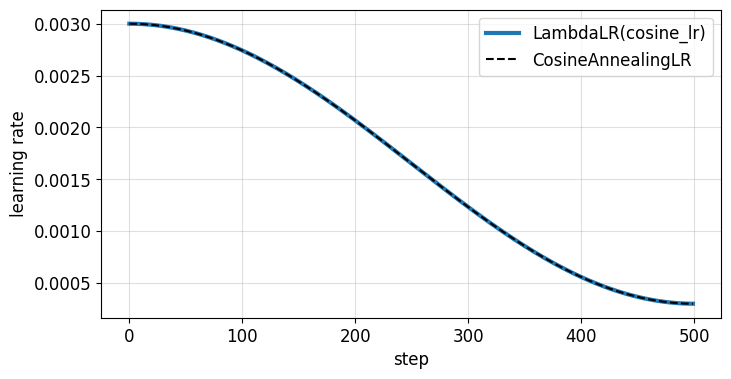

In [33]:
plt.figure(figsize=(8, 4))
plt.plot(mine, linewidth=3, label='LambdaLR(cosine_lr)')
plt.plot(ref, 'k--', linewidth=1.5, label='CosineAnnealingLR')
plt.xlabel('step')
plt.ylabel('learning rate')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Зачем уменьшать learning rate к концу обучения, если оптимизатор и так адаптивный? Что происходит со стохастическим методом при постоянном шаге около минимума?

**Ответ.** Адаптивность Adam нормирует масштаб градиента по координатам, но не убирает шум мини-батча: около минимума истинный градиент мал, а стохастический — нет, и нормированный шаг $\hat m / \sqrt{\hat v}$ сам по себе не затухает, оставаясь порядка $\eta$. При постоянном шаге стохастический метод не сходится к точке, а блуждает в окрестности минимума, размер которой растёт с $\eta$ (стационарная дисперсия итераций $\propto \eta\, \sigma^2$). Уменьшение lr к концу сжимает эту окрестность и снижает loss — отсюда типичный прирост accuracy на последних эпохах cosine-расписания.

---
# 4. ResNet на CIFAR-10

CIFAR-10: 50 000 + 10 000 цветных картинок $32 \times 32$, 10 классов. Весь датасет хранится одним `uint8`-тензором на `device` (≈ 180 MB), нормализация делается на лету над батчем.

In [34]:
N_TRAIN = 10_000 if FAST_MODE else 50_000
N_TEST = 2_000 if FAST_MODE else 10_000

cifar_train = datasets.CIFAR10(DATA_ROOT, train=True, download=True)
cifar_test = datasets.CIFAR10(DATA_ROOT, train=False, download=True)
CIFAR_CLASSES = cifar_train.classes


def to_tensors(ds, n):
    X = torch.from_numpy(ds.data[:n]).permute(0, 3, 1, 2).contiguous()   # uint8 (N, 3, 32, 32)
    return X.to(device), torch.tensor(ds.targets[:n]).to(device)


X_train, Y_train = to_tensors(cifar_train, N_TRAIN)
X_test, Y_test = to_tensors(cifar_test, N_TEST)
CIFAR_MEAN = (X_train.float() / 255).mean(dim=(0, 2, 3))
CIFAR_STD = (X_train.float() / 255).std(dim=(0, 2, 3))
X_train.shape, X_test.shape, CIFAR_MEAN, CIFAR_STD

(torch.Size([50000, 3, 32, 32]),
 torch.Size([10000, 3, 32, 32]),
 tensor([0.4914, 0.4822, 0.4465], device='cuda:0'),
 tensor([0.2470, 0.2435, 0.2616], device='cuda:0'))

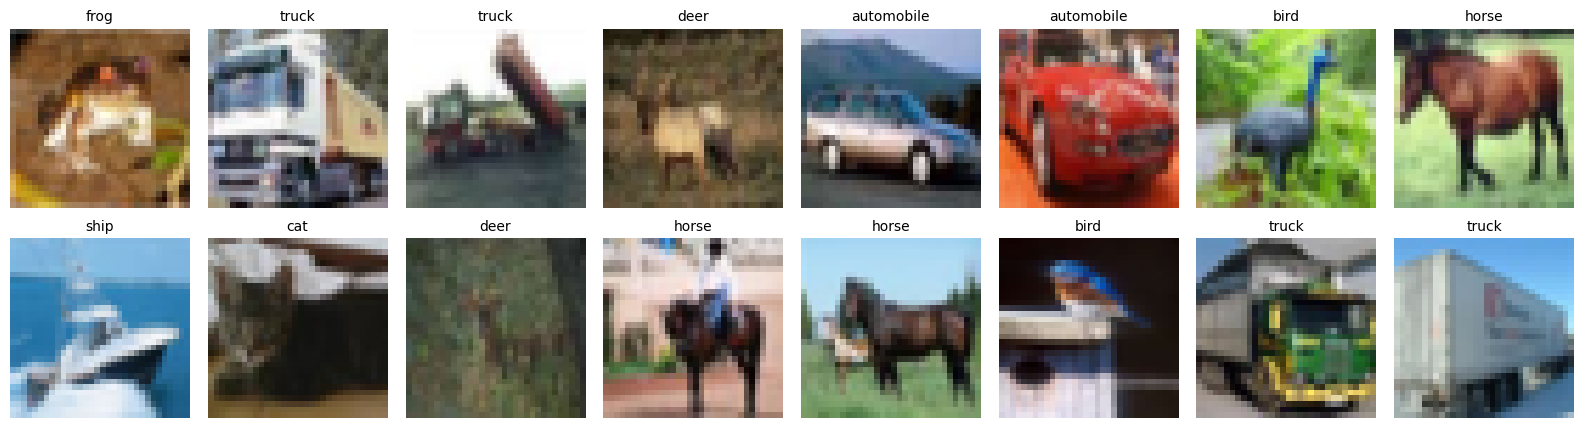

In [35]:
def normalize(x_uint8):
    return (x_uint8.float() / 255 - CIFAR_MEAN[:, None, None]) / CIFAR_STD[:, None, None]


fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.flat, range(16)):
    ax.imshow(X_train[i].permute(1, 2, 0).cpu())
    ax.set_title(CIFAR_CLASSES[Y_train[i]], fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4.1 ResNet для CIFAR (1 балл)

ResNet для CIFAR из §4.2 статьи [Deep Residual Learning for Image Recognition](https://arxiv.org/pdf/1512.03385), He et al., 2015: stem — свёртка $3 \times 3$ на 16 каналов с BN и ReLU; затем три стадии по $n$ блоков шириной 16, 32 и 64; в конце global average pooling и `Linear(64, 10)`. Глубина $6n + 2$. Первый блок второй и третьей стадии — со stride 2.

Блок (свёртки $3 \times 3$ без bias):
$$
F(x) = \mathrm{BN}\Big(\mathrm{Conv}\big(\mathrm{ReLU}(\mathrm{BN}(\mathrm{Conv}(x)))\big)\Big), \qquad y = \mathrm{ReLU}\big(F(x) + \mathrm{shortcut}(x)\big).
$$
Shortcut — `Identity`, а при смене формы (stride 2 или другое число каналов) — свёртка $1 \times 1$ с тем же stride и BN после неё. Флаги:

- `residual=False` — plain-сеть: сложения нет, shortcut-модулей нет;
- `separable=True` — каждая $3 \times 3$ свёртка блоков заменена на depthwise $3 \times 3$ и следующую за ней pointwise $1 \times 1$, обе без bias; stem остаётся обычным.

**Оценивание:** код — 1; эксперимент — 0; объяснение — 0 балла.

In [36]:
def conv3x3(c_in, c_out, stride=1, separable=False):
    if separable:
        return nn.Sequential(nn.Conv2d(c_in, c_in, 3, stride, 1, groups=c_in, bias=False),
                             nn.Conv2d(c_in, c_out, 1, bias=False))
    return nn.Conv2d(c_in, c_out, 3, stride, 1, bias=False)


class Block(nn.Module):
    def __init__(self, c_in, c_out, stride=1, residual=True, separable=False):
        super().__init__()
        self.residual = residual
        self.conv1 = conv3x3(c_in, c_out, stride, separable)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = conv3x3(c_out, c_out, 1, separable)
        self.bn2 = nn.BatchNorm2d(c_out)
        if residual:
            if stride == 1 and c_in == c_out:
                self.shortcut = nn.Identity()
            else:
                self.shortcut = nn.Sequential(nn.Conv2d(c_in, c_out, 1, stride, bias=False), nn.BatchNorm2d(c_out))

    def forward(self, x):
        out = self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x)))))
        if self.residual:
            out = out + self.shortcut(x)
        return F.relu(out)


class ResNetCIFAR(nn.Module):
    def __init__(self, depth=20, residual=True, separable=False, widths=(16, 32, 64), n_classes=10):
        super().__init__()
        assert (depth - 2) % 6 == 0
        n = (depth - 2) // 6
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, padding=1, bias=False),
                                  nn.BatchNorm2d(widths[0]), nn.ReLU())
        blocks, c = [], widths[0]
        for i, w in enumerate(widths):
            for j in range(n):
                blocks.append(Block(c, w, 2 if i > 0 and j == 0 else 1, residual, separable))
                c = w
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(c, n_classes)

    def forward(self, x):
        return self.fc(self.blocks(self.stem(x)).mean(dim=(2, 3)))

In [37]:
x = torch.randn(2, 3, 32, 32)
for depth in [8, 20, 56]:
    for kwargs in [dict(), dict(residual=False), dict(separable=True)]:
        assert ResNetCIFAR(depth, **kwargs)(x).shape == (2, 10), (depth, kwargs)
assert n_params(ResNetCIFAR(20)) == 272_474
assert n_params(ResNetCIFAR(20, residual=False)) == 269_722
{name: n_params(ResNetCIFAR(depth, **kwargs)) for name, depth, kwargs in
 [('ResNet-20', 20, {}), ('ResNet-56', 56, {}), ('ResNet-20, separable', 20, dict(separable=True))]}

{'ResNet-20': 272474, 'ResNet-56': 855770, 'ResNet-20, separable': 40522}

## 4.2 Обучение (2 балла)

Реализуйте `train_cifar`: `MyAdamW` из 3.2 (weight decay только для параметров с `ndim > 1`), `LambdaLR` с `cosine_lr` из 3.3 до нуля за всё обучение ($r = 0$), cross-entropy, батч 256. После каждой эпохи — test accuracy. Вернуть историю `dict(train_loss, test_acc)` по эпохам.

Для ResNet-20 при `FAST_MODE = False` ориентир test accuracy — `TARGET_ACC` за `EPOCHS` эпох с `LR`. Это диагностический ориентир, не жёсткий порог балла: при заметном отставании проверьте normalisation, train/eval, scheduler и loss и опишите результат. Аугментации в этом протоколе нет. Каждый батч нормируйте через `normalize`; `scheduler.step()` вызывается после каждого `optimizer.step()`, `train_loss` — среднее по объектам за эпоху.

Test используется для учебных кривых с заранее фиксированными гиперпараметрами. Если выбираете гиперпараметры самостоятельно, выделите validation из train; test не используйте для выбора конфигурации.

**Оценивание:** код — 1.1; эксперимент — 0.6; объяснение — 0.3 балла.

In [38]:
EPOCHS = 3 if FAST_MODE else 20
LR = 0.003
TARGET_ACC = 0.82


def train_cifar(model, epochs, lr, weight_decay=0.05, batch_size=256, log=True):
    model = model.to(device)
    history = dict(train_loss=[], test_acc=[])
    start = time.time()
    params = list(model.parameters())
    optimizer = MyAdamW([dict(params=[p for p in params if p.ndim > 1], weight_decay=weight_decay),
                         dict(params=[p for p in params if p.ndim <= 1], weight_decay=0.0)], lr=lr)
    total_steps = epochs * math.ceil(len(X_train) / batch_size)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda t: cosine_lr(t, total_steps))
    for epoch in range(epochs):
        model.train()
        total = torch.zeros((), device=device)
        for x, y in iterate_batches(X_train, Y_train, batch_size, transform=normalize):
            loss = F.cross_entropy(model(x), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            scheduler.step()
            total += loss.detach() * len(y)
        history['train_loss'].append(total.item() / len(X_train))
        history['test_acc'].append(accuracy(predict_logits(model, X_test, transform=normalize), Y_test))
        if log:
            print(f'epoch {epoch + 1}/{epochs}  train loss {history["train_loss"][-1]:.4f}  '
                  f'test acc {history["test_acc"][-1]:.4f}  {time.time() - start:.0f}s')
    return history

In [39]:
set_seed(0)
resnet20 = ResNetCIFAR(20)
started = time.perf_counter()
history = train_cifar(resnet20, EPOCHS, LR)
RUN_TIMES['cifar_resnet20_seconds'] = time.perf_counter() - started
history_cifar = history
test_acc = history['test_acc'][-1]
train_acc = accuracy(predict_logits(resnet20, X_train[:10_000], transform=normalize), Y_train[:10_000])
if not FAST_MODE and test_acc < TARGET_ACC:
    print(f'Accuracy {test_acc:.3f} ниже ориентира {TARGET_ACC:.2f}: проверьте протокол и обсудите результат.')
{'train acc': train_acc, 'test acc': test_acc}

epoch 1/20  train loss 1.4358  test acc 0.5528  16s
epoch 2/20  train loss 0.9489  test acc 0.5880  32s
epoch 3/20  train loss 0.7452  test acc 0.7147  48s
epoch 4/20  train loss 0.6310  test acc 0.5996  65s
epoch 5/20  train loss 0.5485  test acc 0.7604  81s
epoch 6/20  train loss 0.4835  test acc 0.7920  98s
epoch 7/20  train loss 0.4206  test acc 0.7456  115s
epoch 8/20  train loss 0.3639  test acc 0.7662  132s
epoch 9/20  train loss 0.3113  test acc 0.8023  150s
epoch 10/20  train loss 0.2583  test acc 0.8127  168s
epoch 11/20  train loss 0.2027  test acc 0.8181  185s
epoch 12/20  train loss 0.1541  test acc 0.8103  202s
epoch 13/20  train loss 0.1050  test acc 0.8118  220s
epoch 14/20  train loss 0.0656  test acc 0.8311  238s
epoch 15/20  train loss 0.0386  test acc 0.8291  256s
epoch 16/20  train loss 0.0243  test acc 0.8307  273s
epoch 17/20  train loss 0.0161  test acc 0.8343  291s
epoch 18/20  train loss 0.0132  test acc 0.8318  309s
epoch 19/20  train loss 0.0113  test acc 0.

{'train acc': 0.9997999668121338, 'test acc': 0.8331999778747559}

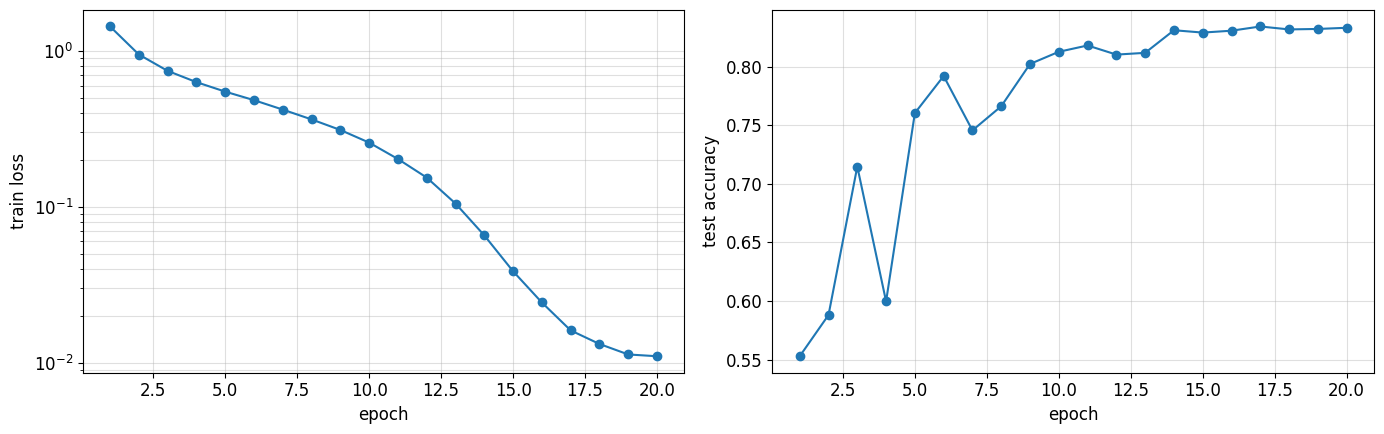

In [40]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
epochs_axis = range(1, len(history['test_acc']) + 1)
ax1.semilogy(epochs_axis, history['train_loss'], 'o-')
ax1.set_ylabel('train loss')
ax2.plot(epochs_axis, history['test_acc'], 'o-')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
plt.tight_layout()
plt.show()

**Вопрос.** Какой разрыв между train и test accuracy в конце обучения? Как ведут себя train loss и test accuracy на последних эпохах, когда learning rate уходит к нулю?

**Ответ.** В конце обучения train accuracy 0.9998, test 0.8332 — разрыв ≈ 16.7 п.п., модель почти запомнила train без аугментаций. Пока lr большой, test accuracy скачет (0.7147 → 0.5996 на 3–4 эпохах), а когда lr уходит к нулю, train loss продолжает падать на порядок (0.258 на 10-й эпохе, 0.0110 на 20-й), а test accuracy выходит на плато: 0.829–0.834 на 14–20-й эпохах. Ориентир 0.82 достигнут; дальнейшее снижение train loss в конце — уже подгонка под train, а не рост качества на test.

## 4.3 Абляции (1.5 балла)

Сравните **plain-20 и plain-56** при одинаковых `ABL_EPOCHS` и `LR`. Это два дополнительных обучения. Результат — `ablation[name] = dict(params, train_acc, test_acc, minutes, history)`, где `train_acc` считается на первых 10 000 объектах train, а `history` возвращается `train_cifar`.

Перед каждой конфигурацией вызовите `set_seed(0)`. Проверяем гипотезу: увеличение глубины plain-сети может затруднить оптимизацию даже на train ([He et al., 2015](https://arxiv.org/pdf/1512.03385)). Это не обещание, что при данном optimizer и коротком бюджете эффект обязательно появится. Отличайте результат «хуже на train» от «лучше на train, хуже на test». Для сравнения с residual-сетями нужен одинаковый протокол; основной ResNet-20 обучался дольше, его финальную accuracy нельзя напрямую трактовать как контроль этого опыта.

**Оценивание:** код — 0.2; эксперимент — 0.7; объяснение — 0.6 балла.

In [41]:
ABL_EPOCHS = 2 if FAST_MODE else 10
ABLATIONS = {
    'plain-20': dict(depth=20, residual=False),
    'plain-56': dict(depth=56, residual=False),
}

In [42]:
ablation = {}
for name, kwargs in ABLATIONS.items():
    print(name)
    set_seed(0)
    model = ResNetCIFAR(**kwargs)
    started = time.perf_counter()
    hist = train_cifar(model, ABL_EPOCHS, LR)
    minutes = (time.perf_counter() - started) / 60
    train_acc = accuracy(predict_logits(model, X_train[:10_000], transform=normalize), Y_train[:10_000])
    ablation[name] = dict(params=n_params(model), train_acc=train_acc, test_acc=hist['test_acc'][-1],
                          minutes=minutes, history=hist)

print(f'{"model":<22}{"params":>9}{"train acc":>11}{"test acc":>10}{"minutes":>9}')
for name, res in ablation.items():
    print(f'{name:<22}{res["params"]:>9,}{res["train_acc"]:>11.4f}{res["test_acc"]:>10.4f}{res["minutes"]:>9.1f}')

plain-20
epoch 1/10  train loss 1.7348  test acc 0.3637  17s
epoch 2/10  train loss 1.4064  test acc 0.3834  34s
epoch 3/10  train loss 1.1375  test acc 0.5915  51s
epoch 4/10  train loss 0.9487  test acc 0.6567  68s
epoch 5/10  train loss 0.8116  test acc 0.7030  85s
epoch 6/10  train loss 0.6983  test acc 0.7269  103s
epoch 7/10  train loss 0.6056  test acc 0.7609  120s
epoch 8/10  train loss 0.5317  test acc 0.7700  137s
epoch 9/10  train loss 0.4774  test acc 0.7815  155s
epoch 10/10  train loss 0.4493  test acc 0.7840  173s
plain-56
epoch 1/10  train loss 1.9691  test acc 0.2299  53s
epoch 2/10  train loss 1.8120  test acc 0.2893  107s
epoch 3/10  train loss 1.7198  test acc 0.2617  160s
epoch 4/10  train loss 1.6938  test acc 0.3644  213s
epoch 5/10  train loss 1.5952  test acc 0.3421  265s
epoch 6/10  train loss 1.5299  test acc 0.3997  318s
epoch 7/10  train loss 1.4354  test acc 0.4600  371s
epoch 8/10  train loss 1.3558  test acc 0.4978  424s
epoch 9/10  train loss 1.2934  te

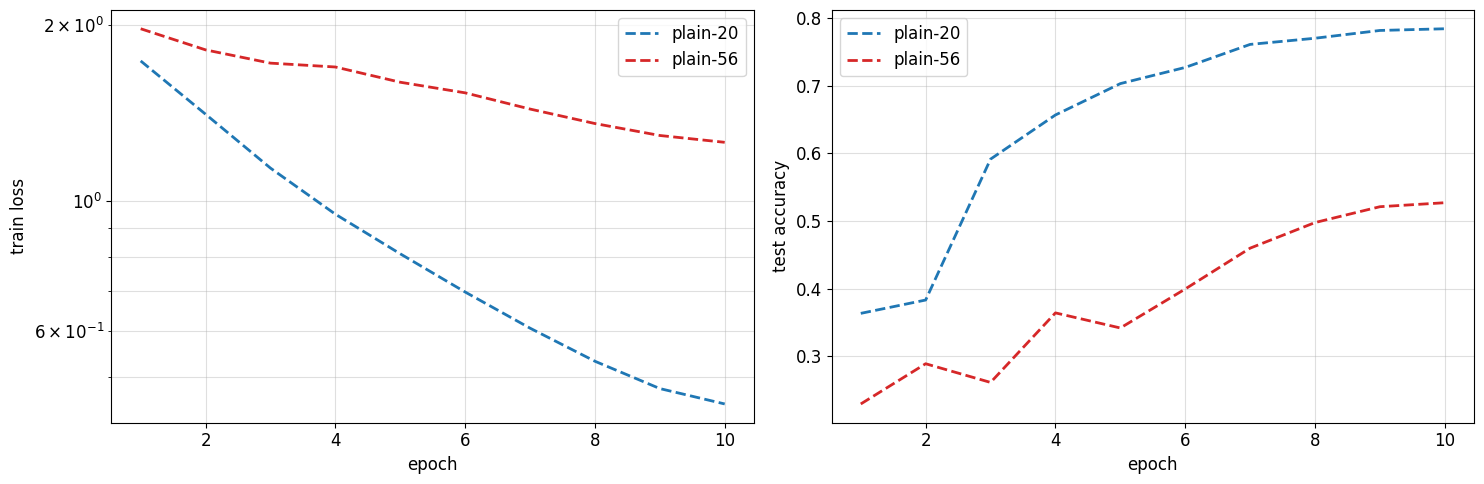

In [43]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
for name in ABLATIONS:
    hist = ablation[name]['history']
    style = '-' if name.startswith('ResNet') else '--'
    color = 'tab:blue' if '20' in name else 'tab:red'
    epochs_axis = range(1, len(hist['train_loss']) + 1)
    ax1.semilogy(epochs_axis, hist['train_loss'], style, color=color, linewidth=2, label=name)
    ax2.plot(epochs_axis, hist['test_acc'], style, color=color, linewidth=2, label=name)
ax1.set_ylabel('train loss')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
    ax.legend()
plt.tight_layout()
plt.show()

**Вопрос.** Есть ли в вашем прогоне ухудшение train loss при увеличении глубины? Как изменились train и test accuracy? Какие наблюдения говорят о трудностях оптимизации, а какие — о переобучении? Если ухудшения на train нет, напишите это. Предложите **один** следующий контрольный эксперимент, позволяющий проверить ваше объяснение; запускать его не требуется.

**Ответ.** Да, ухудшение на train есть: после 10 эпох train loss у plain-56 1.259 против 0.449 у plain-20, train accuracy 0.540 против 0.854, test 0.527 против 0.784. Глубокая сеть хуже на обоих множествах при почти нулевом разрыве train–test (1.3 п.п. против 7 п.п. у plain-20), хотя параметров у неё в 3.2 раза больше, — это признак трудностей оптимизации (недообучение), а не переобучения: переобучение выглядело бы как «лучше на train, хуже на test». Ограничение — один seed и короткий бюджет: plain-56 может просто сходиться медленнее. Контрольный эксперимент: обучить ResNet-56 (`residual=True`) по тому же протоколу; если он догонит или обгонит plain-20 по train loss, проблема в оптимизации глубокой plain-сети, а не в ёмкости или бюджете.

---
# 5. Атаки

Модель — маленькая CNN на FashionMNIST (пиксели в $[0, 1]$, без `Normalize`). В финальном режиме модель учится на полном train, а серии атак идут по фиксированным 1000 test-объектам. Раздел 5.1 обязателен; далее выполняется только ветка, выбранная в `ATTACK_TRACK`. Все модели во время оценки атак находятся в `eval()`. Метрики на такой подвыборке имеют sampling noise; близкие результаты не следует ранжировать как надёжное преимущество.

In [44]:
N_FM_TRAIN = 12_000 if FAST_MODE else 60_000
N_FM_TEST = 256 if FAST_MODE else 1_000
FM_EPOCHS = 2 if FAST_MODE else 5

fm_train = datasets.FashionMNIST(DATA_ROOT, train=True, download=True)
fm_test = datasets.FashionMNIST(DATA_ROOT, train=False, download=True)
FM_CLASSES = fm_train.classes


def fm_tensors(ds, n):
    return (ds.data[:n, None].float() / 255).to(device), ds.targets[:n].to(device)


XF_train, YF_train = fm_tensors(fm_train, N_FM_TRAIN)
XF_test, YF_test = fm_tensors(fm_test, N_FM_TEST)
XF_train.shape, XF_test.shape

(torch.Size([60000, 1, 28, 28]), torch.Size([1000, 1, 28, 28]))

Модель, обучение и атаки FGSM и PGD в $L_\infty$ — готовый код:

In [45]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Linear(64 * 7 * 7, n_classes)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


def train_fm(model, epochs=FM_EPOCHS, lr=1e-3):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        model.train()
        for x, y in iterate_batches(XF_train, YF_train, 128):
            loss = F.cross_entropy(model(x), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    model.eval()
    return model

In [46]:
def fgsm_attack(model, x, y, eps):
    x = x.detach()
    x_adv = x.clone().requires_grad_(True)
    with torch.enable_grad():
        grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
    return (x + eps * grad.sign()).clamp(0, 1).detach()


def pgd_attack(model, x, y, eps, alpha, steps, random_start=True):
    x = x.detach()
    x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1) if random_start else x.clone()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        x_adv = x_adv.detach() + alpha * grad.sign()
        x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)
    return x_adv.detach()


def pgd(model, x, y, eps, steps=20):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / steps, steps=steps)


def attack_accuracy(model, X, Y, attack=None, batch_size=500, **attack_kwargs):
    model.eval()
    correct = 0
    for i in range(0, len(X), batch_size):
        x, y = X[i:i + batch_size], Y[i:i + batch_size]
        if attack is not None:
            x = attack(model, x, y, **attack_kwargs)
        with torch.no_grad():
            correct += (model(x).argmax(dim=1) == y).sum().item()
    return correct / len(X)


def assert_no_param_grads(model):
    assert all(p.grad is None for p in model.parameters())

In [47]:
set_seed(0)
started = time.perf_counter()
model_a = train_fm(SmallCNN())
RUN_TIMES['fashion_standard_seconds'] = time.perf_counter() - started
model_a.zero_grad(set_to_none=True)
{'clean': attack_accuracy(model_a, XF_test, YF_test),
 'FGSM, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, fgsm_attack, eps=0.1),
 'PGD-20, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)}

{'clean': 0.919, 'FGSM, eps=0.1': 0.071, 'PGD-20, eps=0.1': 0.007}

## 5.1 PGD в $L_2$ (1 балл)

Ограничение $\|\delta\|_2 \le \varepsilon$. Линеаризация loss (как при выводе FGSM) даёт шаг по нормированному градиенту, а проекция на шар — масштабирование:
$$
x' = x^{(k)} + \alpha\, \frac{g}{\|g\|_2}, \qquad
\delta = x' - x, \qquad
x^{(k+1)} = \mathrm{clip}_{[0, 1]}\Big(x + \delta \cdot \min\big(1,\, \tfrac{\varepsilon}{\|\delta\|_2}\big)\Big).
$$
Нормы — по каждой картинке отдельно. Старт из $x$ (без random start).

**Оценивание:** код — 0.6; эксперимент — 0.2; объяснение — 0.2 балла.

In [48]:
def pgd_l2(model, x, y, eps, alpha, steps):
    x = x.detach()
    x_adv = x.clone()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        g_norm = grad.flatten(1).norm(dim=1).clamp_min(1e-12).view(-1, 1, 1, 1)
        delta = x_adv.detach() + alpha * grad / g_norm - x
        d_norm = delta.flatten(1).norm(dim=1).clamp_min(1e-12).view(-1, 1, 1, 1)
        x_adv = (x + delta * torch.clamp(eps / d_norm, max=1)).clamp(0, 1)
    return x_adv.detach()

In [49]:
x, y = XF_test[:500], YF_test[:500]
eps2 = 2.0
x_adv = pgd_l2(model_a, x, y, eps=eps2, alpha=2.5 * eps2 / 20, steps=20)
assert (x_adv - x).flatten(1).norm(dim=1).max() <= eps2 + 1e-4
assert x_adv.min() >= 0 and x_adv.max() <= 1 and not x_adv.requires_grad
assert_no_param_grads(model_a)
acc_clean, acc_l2 = attack_accuracy(model_a, x, y), attack_accuracy(model_a, x_adv, y)
print(f'Падение accuracy под PGD-L2: {acc_clean - acc_l2:.3f}; маленькое падение требует диагностики.')
acc_clean, acc_l2

Падение accuracy под PGD-L2: 0.924; маленькое падение требует диагностики.


(0.924, 0.0)

In [50]:
def pgd_l2_20(model, x, y, eps):
    return pgd_l2(model, x, y, eps, alpha=2.5 * eps / 20, steps=20)


eps_l2 = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0]
acc_l2 = [attack_accuracy(model_a, XF_test, YF_test, pgd_l2_20, eps=e) for e in eps_l2]
acc_linf = attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)
dict(zip(eps_l2, acc_l2)), acc_linf

({0.0: 0.919, 0.5: 0.444, 1.0: 0.078, 1.5: 0.01, 2.0: 0.0, 3.0: 0.0, 4.0: 0.0},
 0.006)

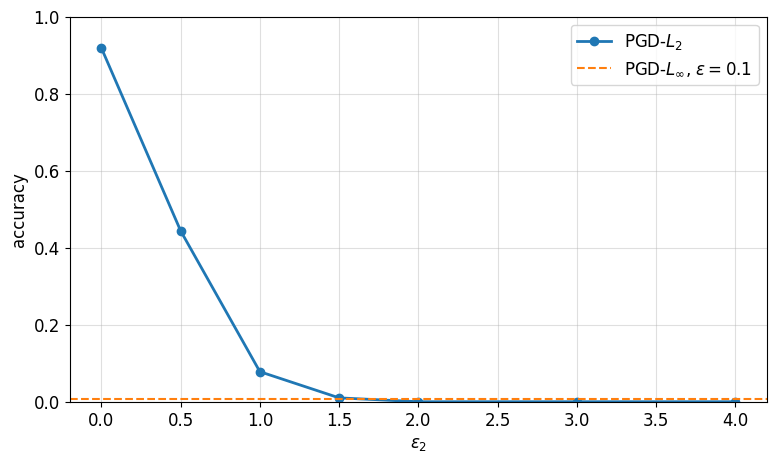

In [51]:
plt.figure(figsize=(9, 5))
plt.plot(eps_l2, acc_l2, 'o-', linewidth=2, label=r'PGD-$L_2$')
plt.axhline(acc_linf, color='tab:orange', linestyle='--', label=r'PGD-$L_\infty$, $\varepsilon = 0.1$')
plt.xlabel(r'$\varepsilon_2$')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

Возмущения обеих атак на одних картинках; $\varepsilon_2$ — ближайшая по accuracy точка проверенной сетки. Если разница велика, сравнение не следует называть сравнением при равной силе атаки. Цветовая шкала каждой карты нормирована отдельно; абсолютные нормы выведены под рисунком:

Ближайшая точка сетки: eps2=1.5, accuracy gap=0.004


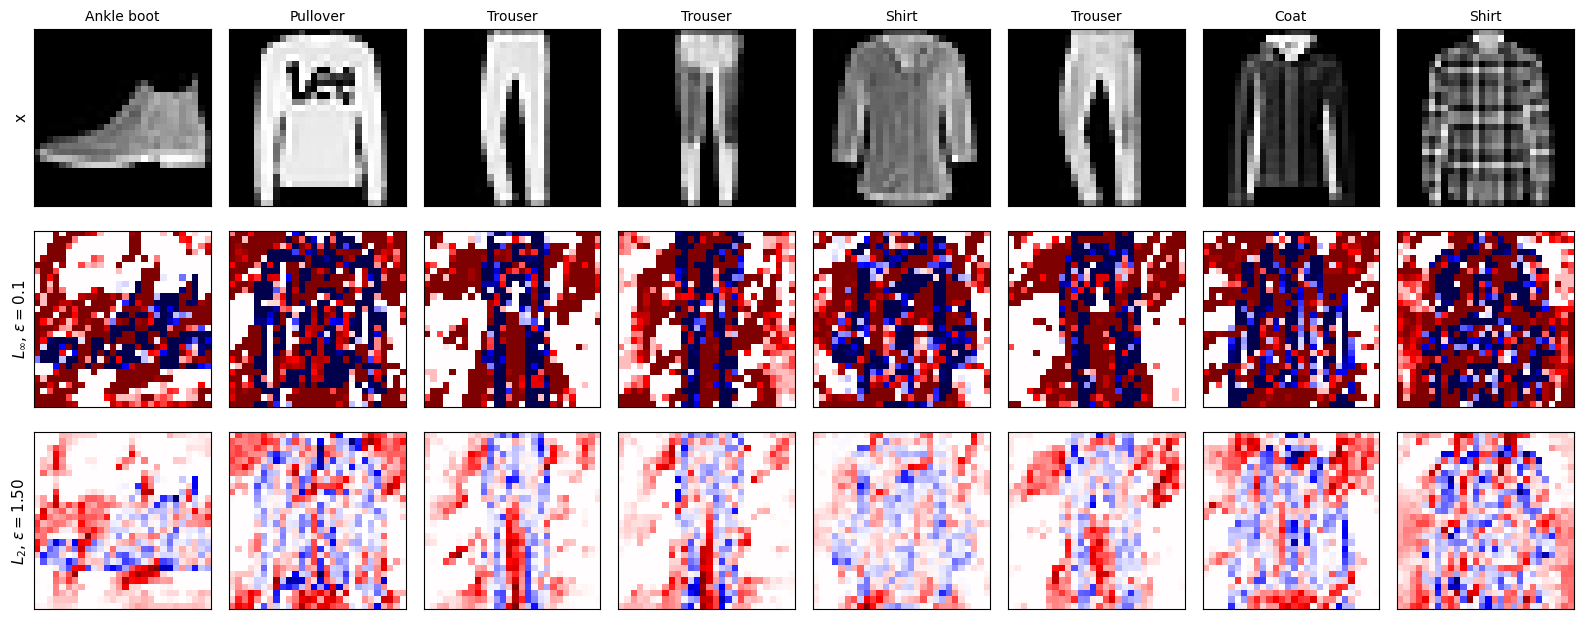

$L_\infty$, $\varepsilon=0.1$ L_inf = 0.100   L_2 = 2.104
$L_2$, $\varepsilon=1.50$    L_inf = 0.253   L_2 = 1.492


In [52]:
# Поиск ближайшей проверенной точки не предполагает монотонность конечной PGD.
match_idx = int(np.argmin(np.abs(np.asarray(acc_l2) - acc_linf)))
eps2_match = float(eps_l2[match_idx])
print(f'Ближайшая точка сетки: eps2={eps2_match}, accuracy gap={abs(acc_l2[match_idx] - acc_linf):.3f}')
x8, y8 = XF_test[:8], YF_test[:8]
torch.manual_seed(0)
deltas = {r'$L_\infty$, $\varepsilon=0.1$': pgd(model_a, x8, y8, 0.1) - x8,
          rf'$L_2$, $\varepsilon={eps2_match:.2f}$': pgd_l2_20(model_a, x8, y8, eps2_match) - x8}
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for i in range(8):
    axes[0, i].imshow(x8[i, 0].cpu(), cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title(FM_CLASSES[y8[i]], fontsize=10)
    for row, d in enumerate(deltas.values(), start=1):
        vmax = d[i].abs().max().item()
        axes[row, i].imshow(d[i, 0].cpu(), cmap='seismic', vmin=-vmax, vmax=vmax)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
for ax, label in zip(axes[:, 0], ['x'] + list(deltas)):
    ax.set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()
for name, d in deltas.items():
    print(f'{name:<28} L_inf = {d.abs().amax(dim=(1, 2, 3)).mean():.3f}   L_2 = {d.flatten(1).norm(dim=1).mean():.3f}')

**Вопрос.** Какая точка сетки $\varepsilon_2$ ближе всего по accuracy к $L_\infty$-атаке с $\varepsilon = 0.1$ и как велик остаточный разрыв? Какова $L_2$-норма самого $L_\infty$-возмущения? Где сосредоточено $L_2$-возмущение на ваших изображениях и как это связано с нормированным градиентом?

**Ответ.** Ближайшая точка сетки — $\varepsilon_2 = 1.5$: accuracy 0.010 против 0.006 у $L_\infty$-атаки с $\varepsilon = 0.1$, разрыв 0.004. Сама $L_\infty$-атака имеет $L_2$-норму ≈ 2.10 (меньше максимума $0.1 \sqrt{784} = 2.8$, потому что на чёрном фоне пиксели нельзя уменьшить и часть шагов срезается clip), то есть при равной accuracy $L_2$-атаке хватает меньшей нормы, но с $L_\infty$-нормой 0.253. На картинках $L_\infty$-возмущение покрывает почти весь кадр, включая фон, а $L_2$-возмущение сосредоточено на объекте и его контурах (между штанинами, по краям силуэта), фон почти не трогается: шаг по нормированному градиенту $g / \|g\|_2$ распределяет бюджет пропорционально величине градиента, тогда как $\mathrm{sign}(g)$ даёт всем пикселям одинаковую амплитуду.

## 5.2 Targeted attack (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'targeted'`. Ветку 5.3 при этом можно оставить пустой.

Цель — не просто ошибка, а заданный класс $t$: минимизируем loss по целевой метке
$$
x^{(k+1)} = \Pi_{B_\infty(x, \varepsilon)}\Big[x^{(k)} - \alpha\, \mathrm{sign}\, \nabla_x L\big(f(x^{(k)}), t\big)\Big].
$$

1. Реализуйте `pgd_targeted` ($L_\infty$, random start, как `pgd_attack`).
2. Реализуйте `targeted_success_matrix`: $S[s, t]$ — доля всех картинок класса $s$, которые после атаки с целью $t$ классифицируются как $t$, включая изначально ошибочные. Верните CPU-тензор; диагональ и строки отсутствующих классов — `nan`. Обрабатывайте вход батчами не более 128 объектов, сигнатуру менять не нужно. Сопоставьте результат с готовой clean confusion matrix ниже.

**Оценивание:** код — 1; эксперимент — 0.4; объяснение — 0.6 балла.

In [53]:
if ATTACK_TRACK == 'targeted':
    def pgd_targeted(model, x, target, eps, alpha, steps):
        x = x.detach()
        x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1)
        for _ in range(steps):
            x_adv.requires_grad_(True)
            with torch.enable_grad():
                grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), target), x_adv)
            x_adv = x_adv.detach() - alpha * grad.sign()
            x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)
        return x_adv.detach()


    def targeted_success_matrix(model, x, y, eps, steps=20, n_classes=10):
        model.eval()
        hits = torch.zeros(n_classes, n_classes)
        counts = torch.bincount(y.cpu(), minlength=n_classes).float()
        for t in range(n_classes):
            for i in range(0, len(x), 128):
                xb, yb = x[i:i + 128], y[i:i + 128]
                x_adv = pgd_targeted(model, xb, torch.full_like(yb, t), eps, alpha=2.5 * eps / steps, steps=steps)
                with torch.no_grad():
                    hit = model(x_adv).argmax(dim=1) == t
                hits[:, t] += torch.bincount(yb[hit].cpu(), minlength=n_classes).float()
        S = hits / counts[:, None]
        S.fill_diagonal_(float('nan'))
        return S

In [54]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    x, y = XF_test[:1000], YF_test[:1000]
    target = (y + 1) % 10
    x_t = pgd_targeted(model_a, x, target, eps=0.1, alpha=0.0125, steps=20)
    assert (x_t - x).abs().max() <= 0.1 + 1e-6 and x_t.min() >= 0 and x_t.max() <= 1
    assert_no_param_grads(model_a)
    with torch.no_grad():
        hit_rate = (model_a(x_t).argmax(dim=1) == target).float().mean().item()
    print(f'Targeted hit rate: {hit_rate:.3f}; сравните с частотой целевого класса до атаки.')
    hit_rate

Targeted hit rate: 0.766; сравните с частотой целевого класса до атаки.


Clean confusion matrix (строки: true, столбцы: predicted):
[[0.93 0.   0.01 0.03 0.   0.   0.03 0.   0.   0.  ]
 [0.   0.99 0.   0.01 0.   0.   0.   0.   0.   0.  ]
 [0.04 0.   0.86 0.01 0.05 0.   0.05 0.   0.   0.  ]
 [0.05 0.   0.01 0.88 0.03 0.   0.02 0.   0.   0.  ]
 [0.   0.   0.06 0.03 0.89 0.   0.03 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.98 0.   0.01 0.   0.01]
 [0.09 0.   0.06 0.03 0.06 0.   0.75 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.99 0.01 0.  ]
 [0.   0.   0.   0.   0.   0.   0.01 0.   0.99 0.  ]
 [0.   0.   0.   0.   0.   0.01 0.   0.04 0.   0.95]]


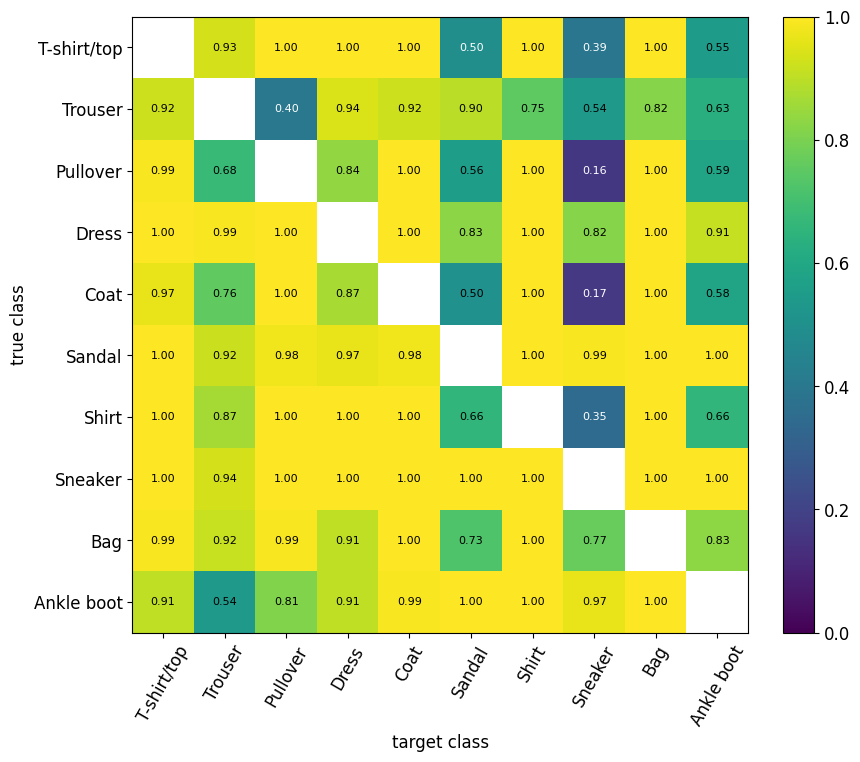

In [55]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    S = targeted_success_matrix(model_a, XF_test, YF_test, eps=0.1)
    assert S.shape == (10, 10) and torch.isnan(S.diagonal()).all()
    pred_clean = predict_logits(model_a, XF_test).argmax(1)
    clean_confusion = torch.bincount((10 * YF_test + pred_clean).cpu(), minlength=100).reshape(10, 10).float()
    clean_confusion /= clean_confusion.sum(1, keepdim=True).clamp_min(1)
    print('Clean confusion matrix (строки: true, столбцы: predicted):')
    print(np.round(clean_confusion.numpy(), 2))

    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(S, cmap='viridis', vmin=0, vmax=1)
    for s, t in itertools.product(range(10), range(10)):
        if s != t:
            ax.text(t, s, f'{S[s, t]:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if S[s, t] < 0.5 else 'black')
    ax.set_xticks(range(10), FM_CLASSES, rotation=60)
    ax.set_yticks(range(10), FM_CLASSES)
    ax.set_xlabel('target class')
    ax.set_ylabel('true class')
    plt.colorbar(im, fraction=0.046)
    plt.show()

**Вопрос.** Какие пары (истинный класс, целевой класс) атакуются легче всего, какие труднее? Симметрична ли матрица? Как это связано с тем, какие классы модель путает без атаки?

**Ответ.** Атака сильная: среднее по недиагональным клеткам $S$ — 0.87, hit rate для цели $(y + 1) \bmod 10$ — 0.766 при частоте каждого класса до атаки около 10%. Труднее всего увести одежду в обувь: Pullover → Sneaker 0.16, Coat → Sneaker 0.17, Shirt → Sneaker 0.35, T-shirt → Sneaker 0.39, а также Trouser → Pullover 0.40; цель Sneaker самая трудная (среднее по столбцу 0.57), затем Sandal и Ankle boot (0.74–0.75). Легче всего атакуются строки обуви (Sneaker 0.99, Sandal 0.98 в среднем) и цели T-shirt, Coat, Shirt, Bag (0.97–0.99). Матрица несимметрична (среднее $|S - S^\top| = 0.19$), например Sneaker → Pullover 1.00, а Pullover → Sneaker 0.16. Пары, которые модель путает без атаки (Shirt → T-shirt 0.09, Pullover ↔ Coat 0.05–0.06, Shirt → Coat 0.06), атакуются почти всегда (≈ 1.0), а самые трудные пары — те, что на clean не путаются никогда (0.00). При $\varepsilon = 0.1$ почти все пары насыщены, поэтому clean confusion объясняет в основном «хвост» трудных пар; гипотеза для асимметрии — большой яркий силуэт кофты нельзя превратить в силуэт кроссовка в пределах ±0.1, а у маленькой обуви на тёмном фоне много свободных пикселей, где можно нарисовать нужные признаки.

## 5.3 Transfer (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'transfer'`. Ветку 5.2 при этом можно оставить пустой.

Black-box сценарий: атакующий не видит модель-жертву, строит атаку на своей модели и надеется, что она перенесётся. Обучите `model_b` (та же архитектура, `set_seed(1)`) и MLP с двумя скрытыми слоями по 512 нейронов и ReLU (`set_seed(2)`). Атаки FGSM и PGD-20 с $\varepsilon = 0.1$, построенные на `model_a`, проверьте на всех трёх моделях. Результат — `transfer[attack][victim] = accuracy`, атаки `'clean'`, `'FGSM'`, `'PGD-20'`, жертвы `'model A (source)'`, `'model B'`, `'MLP'`.

**Оценивание:** код — 0.6; эксперимент — 0.8; объяснение — 0.6 балла.

In [56]:
if ATTACK_TRACK == 'transfer':
    # ваш код
    raise NotImplementedError
    print(f'{"":<8}' + ''.join(f'{name:>18}' for name in transfer['clean']))
    for attack, row in transfer.items():
        print(f'{attack:<8}' + ''.join(f'{acc:>18.3f}' for acc in row.values()))

**Вопрос.** Для каждой жертвы укажите падение accuracy относительно её собственного clean baseline. Сравните с падением на source-модели. Какая атака и на какую архитектуру переносится лучше в вашем прогоне? Предложите объяснение и укажите, почему одного seed недостаточно для общего вывода о превосходстве архитектуры или атаки.

**Ответ.**

---
# 6. Adversarial training

## 6.1 PGD adversarial training (2 балла)

[Towards Deep Learning Models Resistant to Adversarial Attacks](https://arxiv.org/pdf/1706.06083), Madry et al., 2017:
$$
\min_\theta\; \mathbb E_{(x, y)} \Big[\max_{\|\delta\|_\infty \le \varepsilon} L\big(f_\theta(x + \delta), y\big)\Big].
$$
На каждом батче внутренний max приближается атакой, и шаг оптимизатора делается только по adversarial-примерам, без clean-части. Модель — с нуля.

Реализуйте `adversarial_train(model, eps, attack, epochs)`: `attack(model, x, y, eps)` возвращает detached `x_adv`. Используйте `torch.optim.Adam` с переданным `lr`, batch size 128, cross-entropy только на adversarial-примерах. Генерация атаки — в `eval()`, обновление весов — в `train()`; не дифференцируйте через построение атаки. После каждой эпохи записывайте clean, FGSM и PGD-20 accuracy на `XF_test[:1000]` с тем же $\varepsilon$. Перед возвратом включите `eval()` и очистите `.grad` параметров.

В обязательной части обучается одна модель с PGD-7. FGSM и FGSM-RS из готового словаря нужны только для бонуса 7.5.

**Оценивание:** код — 1; эксперимент — 0.6; объяснение — 0.4 балла.

In [57]:
def fgsm_rs_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=1.25 * eps, steps=1, random_start=True)


def pgd7_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / 7, steps=7)


TRAIN_ATTACKS = {'FGSM': fgsm_attack, 'FGSM-RS': fgsm_rs_attack, 'PGD-7': pgd7_attack}
AT_EPOCHS = 2 if FAST_MODE else 5

In [58]:
def adversarial_train(model, eps, attack, epochs=AT_EPOCHS, lr=1e-3, log=True):
    model = model.to(device)
    history = dict(clean=[], fgsm=[], pgd=[])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    x_val, y_val = XF_test[:1000], YF_test[:1000]
    start = time.time()
    for epoch in range(epochs):
        for x, y in iterate_batches(XF_train, YF_train, 128):
            model.eval()
            x_adv = attack(model, x, y, eps)
            model.train()
            loss = F.cross_entropy(model(x_adv), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        history['clean'].append(attack_accuracy(model, x_val, y_val))
        history['fgsm'].append(attack_accuracy(model, x_val, y_val, fgsm_attack, eps=eps))
        history['pgd'].append(attack_accuracy(model, x_val, y_val, pgd, eps=eps))
        if log:
            print(f'epoch {epoch + 1}/{epochs}  clean {history["clean"][-1]:.3f}  fgsm {history["fgsm"][-1]:.3f}  '
                  f'pgd {history["pgd"][-1]:.3f}  {time.time() - start:.0f}s')
    model.eval()
    model.zero_grad(set_to_none=True)
    return history

In [59]:
EPS_TRAIN = 0.1
robust, at_history = {}, {}
for name in ['PGD-7']:
    print(name)
    set_seed(0)
    robust[name] = SmallCNN()
    started = time.perf_counter()
    at_history[name] = adversarial_train(robust[name], EPS_TRAIN, TRAIN_ATTACKS[name])
    RUN_TIMES['fashion_pgd_at_seconds'] = time.perf_counter() - started
if not FAST_MODE and at_history['PGD-7']['pgd'][-1] <= 0.5:
    print('PGD accuracy ниже ориентира 0.5: проверьте обучение и обсудите результат; это не автопровал задания.')

PGD-7
epoch 1/5  clean 0.807  fgsm 0.700  pgd 0.664  10s
epoch 2/5  clean 0.822  fgsm 0.699  pgd 0.664  19s
epoch 3/5  clean 0.820  fgsm 0.725  pgd 0.699  29s
epoch 4/5  clean 0.828  fgsm 0.719  pgd 0.698  38s
epoch 5/5  clean 0.841  fgsm 0.746  pgd 0.723  48s


In [60]:
eps_grid = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3]
models_eval = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
torch.manual_seed(0)
robust_curves = {name: [attack_accuracy(m, XF_test, YF_test, pgd, eps=e) if e > 0 else attack_accuracy(m, XF_test, YF_test)
                        for e in eps_grid] for name, m in models_eval.items()}
for name, accs in robust_curves.items():
    print(f'{name:<10}' + ''.join(f'{a:>8.3f}' for a in accs))

standard     0.919   0.122   0.006   0.000   0.000   0.000
PGD-AT       0.841   0.789   0.724   0.475   0.134   0.001


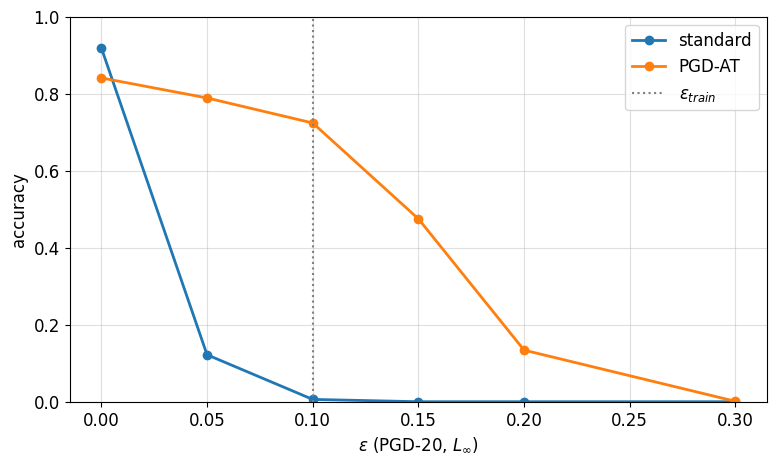

In [61]:
plt.figure(figsize=(9, 5))
for name, accs in robust_curves.items():
    plt.plot(eps_grid, accs, 'o-', linewidth=2, label=name)
plt.axvline(EPS_TRAIN, color='gray', linestyle=':', label=r'$\varepsilon_{train}$')
plt.xlabel(r'$\varepsilon$ (PGD-20, $L_\infty$)')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Сколько стоит робастность в clean accuracy? Что происходит при $\varepsilon > \varepsilon_{\text{train}}$? Во сколько раз PGD-AT дороже обычного обучения по числу forward/backward?

**Ответ.** Робастность стоит 7.8 п.п. clean accuracy: 0.919 у обычной модели против 0.841 у PGD-AT, зато PGD-20 accuracy при $\varepsilon = 0.1$ выросла с 0.006 до 0.724. При $\varepsilon > \varepsilon_{\text{train}}$ робастность быстро теряется: 0.475 при 0.15, 0.134 при 0.2 и 0.001 при 0.3 (у обычной модели уже 0 начиная с 0.15) — защита работает в основном в пределах радиуса обучения. По числу forward/backward PGD-7 AT на каждом батче делает 7 проходов атаки и 1 проход обновления, то есть примерно в 8 раз дороже обычного обучения; по времени вышло 48 с против 7.8 с (≈ 6.2 раза, плюс в AT входит оценка FGSM и PGD-20 после каждой эпохи; шаги атаки дешевле — нет градиентов по параметрам и шага оптимизатора).

## 6.2 Диагностика оценки robustness (1 балл)

Реализуйте `sanity_checks(model, x, y, eps)` и верните четыре accuracy:

- `fgsm` — после FGSM;
- `pgd20` — после PGD-20 с random start;
- `pgd100_x5` — PGD-100 с пятью random restarts: объект считается сломанным, если он ошибочно классифицирован хотя бы в одном restart **или уже на clean**;
- `eps_1` — после PGD-20 с $\varepsilon=1$.

Для каждого поля clean-ошибки тоже считаются ошибками: атака не должна «исправлять» robust accuracy. Атакуйте батчами не более 128. В `FAST_MODE` сокращается только число объектов, число шагов и restarts остаётся тем же.

Обычно усиление атаки уменьшает accuracy; обратный результат — повод проверить step size, random start и loss. Независимые конечные PGD-прогоны не дают гарантированного порядка результатов. Низкая accuracy при большом радиусе — полезная диагностика, но прохождение всех sanity checks не доказывает отсутствие gradient masking и не сертифицирует robustness. См. [Athalye et al., 2018](https://arxiv.org/abs/1802.00420).

Эксперимент проводится на фиксированных первых 128 объектах в FAST_MODE и 256 в финальном режиме. Это диагностика, а не точная оценка accuracy всего датасета.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [62]:
def sanity_checks(model, x, y, eps):
    model.eval()
    res = dict(fgsm=0, pgd20=0, pgd100_x5=0, eps_1=0)
    for i in range(0, len(x), 128):
        xb, yb = x[i:i + 128], y[i:i + 128]
        with torch.no_grad():
            clean_ok = model(xb).argmax(dim=1) == yb

        def survived(x_adv):
            with torch.no_grad():
                return (model(x_adv).argmax(dim=1) == yb) & clean_ok

        res['fgsm'] += survived(fgsm_attack(model, xb, yb, eps)).sum().item()
        res['pgd20'] += survived(pgd(model, xb, yb, eps)).sum().item()
        robust = clean_ok.clone()
        for _ in range(5):
            robust &= survived(pgd(model, xb, yb, eps, steps=100))
        res['pgd100_x5'] += robust.sum().item()
        res['eps_1'] += survived(pgd(model, xb, yb, 1.0)).sum().item()
    return {k: v / len(x) for k, v in res.items()}

In [63]:
torch.manual_seed(0)
N_SANITY = 128 if FAST_MODE else 256
checks = {name: sanity_checks(m, XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_TRAIN)
          for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
print(f'{"model":<22}' + ''.join(f'{k:>11}' for k in next(iter(checks.values()))))
for name, res in checks.items():
    assert set(res) == {'fgsm', 'pgd20', 'pgd100_x5', 'eps_1'}
    assert all(math.isfinite(v) and 0 <= v <= 1 for v in res.values())
    print(f'{name:<22}' + ''.join(f'{v:>11.3f}' for v in res.values()))

model                        fgsm      pgd20  pgd100_x5      eps_1
standard                    0.074      0.012      0.008      0.000
PGD-AT                      0.750      0.730      0.730      0.000


**Вопрос.** Насколько меняется оценка accuracy при усилении атаки? Есть ли подозрительные результаты и что вы проверили бы дополнительно? Может ли модель с высокой FGSM accuracy и почти нулевой PGD accuracy пройти все перечисленные sanity checks — и что тогда можно сказать о её robustness?

**Ответ.** Оценка монотонно убывает при усилении атаки. У обычной модели: FGSM 0.074 → PGD-20 0.012 → PGD-100 × 5 0.008. У PGD-AT: 0.750 → 0.730 → 0.730, то есть 100 шагов и 5 рестартов не находят новых ошибок, а при $\varepsilon = 1$ обе модели дают 0 — атака без ограничения ломает всё, градиент информативен. Подозрительного нет: разрыв FGSM–PGD у PGD-AT мал (2 п.п.), усиление атаки не повышает accuracy. Дополнительно я бы проверил атаки без градиента (например, Square Attack), APGD/AutoAttack с другим loss (CW, DLR) и transfer-атаки с обычной модели. Модель с высокой FGSM и почти нулевой PGD accuracy проходит все эти проверки: порядок FGSM ≥ PGD-20 ≥ PGD-100 × 5 соблюдён, при $\varepsilon = 1$ accuracy 0 — так ведёт себя FGSM-модель из 7.5 (0.406, 0.0, 0.0, 0.0). Её реальная робастность ≈ 0: robust accuracy оценивается сверху минимумом по атакам, а прохождение sanity checks — необходимое, но не достаточное условие.

## 6.3 Градиент по входу у обычной и робастной модели (1 балл)

Карта $|\nabla_x z_y(x)|$ — saliency по логиту верного класса: $z_c(x)$ обозначает логит класса $c$, $y$ — верную метку. Это **другая величина**, чем градиент cross-entropy в FGSM. Если $p_c(x)=\mathrm{softmax}(z(x))_c$, то
$$
\nabla_x L_{\mathrm{CE}}(x,y)=\sum_c p_c(x)\nabla_x z_c(x)-\nabla_x z_y(x).
$$
Для некоторых adversarially trained моделей наблюдали более интерпретируемые input gradients ([Tsipras et al., 2019](https://arxiv.org/pdf/1805.12152)). Здесь проверяется, наблюдается ли такой эффект в нашем протоколе; вид saliency сам по себе не доказывает robustness.

1. Реализуйте `input_gradient(model, x, y)`, возвращающую $|\nabla_x z_y|$ для батча (без изменения `.grad` параметров).
2. Для стандартной модели и PGD-AT посчитайте долю массы градиента на фоне (пиксели с $x = 0$), среднюю по `XF_test[:1000]`, и нарисуйте карты для 8 картинок.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [64]:
def input_gradient(model, x, y):
    model.eval()
    grads = []
    for xi, yi in zip(x, y):
        xi = xi[None].detach().clone().requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(model(xi)[0, yi], xi)
        grads.append(grad.abs())
    return torch.cat(grads)


def background_share(s, x):
    return ((s * (x == 0)).flatten(1).sum(1) / s.flatten(1).sum(1).clamp_min(1e-12)).mean().item()

In [65]:
x, y = XF_test[:1000], YF_test[:1000]
g = input_gradient(model_a, x, y)
assert g.shape == x.shape and (g >= 0).all()
assert_no_param_grads(model_a)
x1 = x[:1].clone().requires_grad_(True)
manual, = torch.autograd.grad(model_a(x1)[0, y[0]], x1)
assert torch.allclose(g[:1], manual.abs())

grad_models = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
shares = {name: background_share(input_gradient(m, x, y), x) for name, m in grad_models.items()}
print(f'background pixels: {(x == 0).float().mean():.3f}')
shares

background pixels: 0.498


{'standard': 0.5900874733924866, 'PGD-AT': 0.2227490246295929}

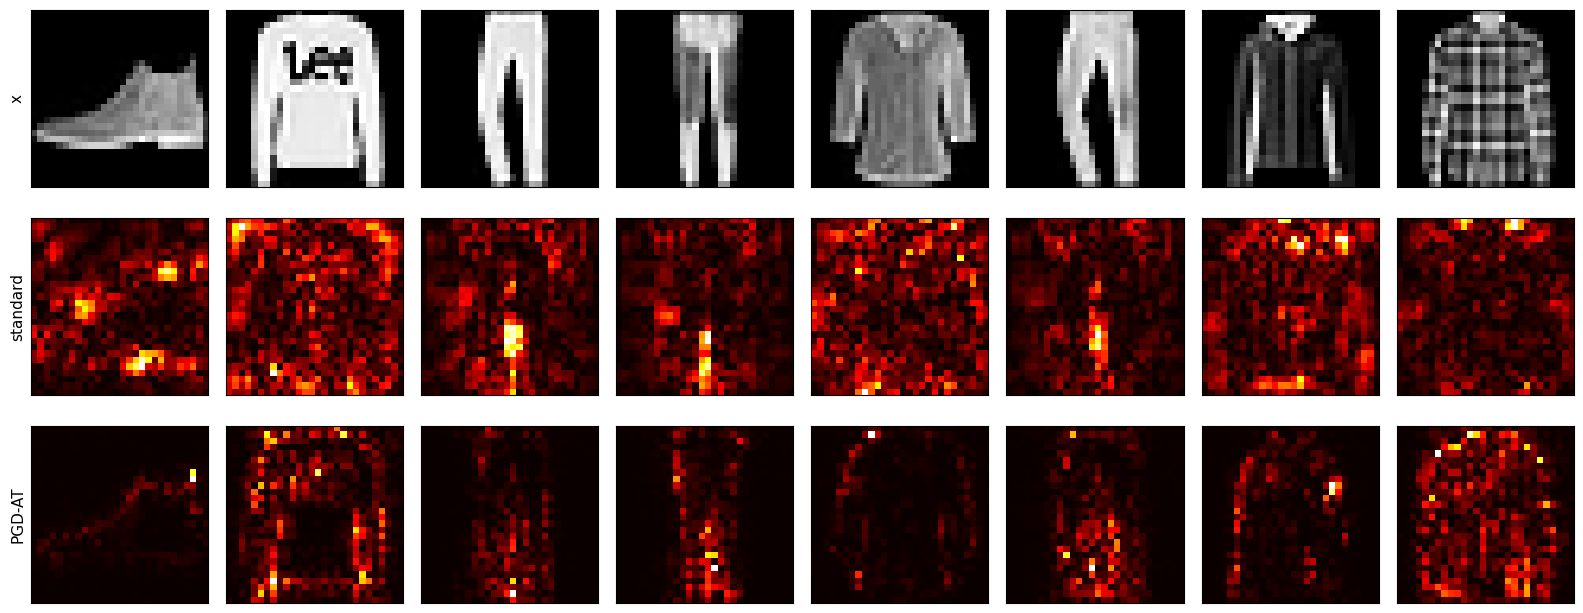

In [66]:
x8, y8 = XF_test[:8], YF_test[:8]
rows = {'x': x8} | {name: input_gradient(m, x8, y8) for name, m in grad_models.items()}
fig, axes = plt.subplots(len(rows), 8, figsize=(16, 2.2 * len(rows)))
for row, (label, images) in enumerate(rows.items()):
    for i in range(8):
        axes[row, i].imshow(images[i, 0].cpu(), cmap='gray' if row == 0 else 'hot')
        axes[row, i].set_xticks([])
        axes[row, i].set_yticks([])
    axes[row, 0].set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()

**Вопрос.** Чем отличаются карты моделей — визуально и по доле массы на фоне? Согласуется ли наблюдение с различием PGD accuracy в вашем эксперименте? Почему одной красивой saliency-карты недостаточно для вывода о robustness?

**Ответ.** У обычной модели карты шумные и разбросаны по всему кадру, с яркими пятнами на фоне (на ботинке — вне силуэта), а у PGD-AT градиент сосредоточен на силуэте и контурах объекта, фон почти тёмный. По доле массы на фоне (фон — 49.8% пикселей): 0.590 у обычной модели против 0.223 у PGD-AT. Это согласуется с разницей PGD accuracy (0.006 против 0.724): робастная модель мало чувствительна к пикселям фона, через которые $L_\infty$-атака могла бы её сломать. Но saliency — это лишь градиент в одной точке, то есть локальная линейная информация, а не гарантия по всему $\varepsilon$-шару: красивая карта совместима с gradient masking и с поломкой более сильной атакой, а визуальная оценка 8 картинок субъективна.

### Сохранение результатов обязательной части

Ячейка сохраняет `metrics.json` и три checkpoint в `artifacts/`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode=false`. Сдайте их вместе с ноутбуком. NaN в матрице targeted success записываются как JSON `null`. Checkpoints содержат только `state_dict`, без сериализации объекта модели.

In [67]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    schema_version=2, fast_mode=FAST_MODE, attack_track=ATTACK_TRACK,
    environment=dict(torch=torch.__version__, device=str(device)),
    data=dict(cifar_train=len(X_train), cifar_test=len(X_test),
              fashion_train=len(XF_train), fashion_test=len(XF_test)),
    config=dict(seed=0, cifar_epochs=EPOCHS, ablation_epochs=ABL_EPOCHS,
                cifar_lr=LR, cifar_mean=CIFAR_MEAN, cifar_std=CIFAR_STD,
                fashion_epochs=FM_EPOCHS, at_epochs=AT_EPOCHS, eps_train=EPS_TRAIN),
    cifar=dict(history=history_cifar, ablations=ablation),
    attacks=dict(l2_eps=eps_l2, l2_accuracy=acc_l2, linf_accuracy=acc_linf,
                 selected=S if ATTACK_TRACK == 'targeted' else transfer),
    adversarial=dict(history=at_history, eps=eps_grid, accuracy=robust_curves,
                     sanity=checks, background_share=shares),
    timings=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2,
                                                    allow_nan=False), encoding='utf-8')
for name, model in [('resnet20', resnet20), ('fashion_standard', model_a), ('fashion_pgd_at', robust['PGD-7'])]:
    torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, artifact_dir / f'{name}.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['fashion_pgd_at.pt', 'fashion_standard.pt', 'metrics.json', 'resnet20.pt']


---
# 7\*. Бонусные задачи

## 7.1 Edge of stability (1.5 балла)

Для положительно определённой квадратичной функции GD сходится при $0 < \eta < 2/\lambda_{\max}$, где $\lambda_{\max}$ — наибольшее собственное число гессиана. [Gradient Descent on Neural Networks Typically Occurs at the Edge of Stability](https://arxiv.org/pdf/2103.00065), Cohen et al., 2021: у нейросети sharpness $\lambda_{\max}(\nabla^2 L)$ во время full-batch GD растёт (progressive sharpening), пока не дойдёт до $2/\eta$, и дальше держится около этой границы — loss при этом немонотонный, но продолжает убывать.

1. Реализуйте `hvp(grads, params, v)`: градиент считается один раз с `create_graph=True`, а $Hv$ — VJP градиента с вектором $v$ (`grad_outputs` в `torch.autograd.grad`); гессиан $H$ явно не строится.
2. `top_eigenvalue` ниже — готовый Lanczos с reorthogonalization. Он оценивает **наибольшее algebraic eigenvalue** через наибольшее eigenvalue небольшой tridiagonal matrix. Обычная power iteration для indefinite Hessian может найти отрицательное eigenvalue с наибольшим модулем и здесь не подходит. Менять готовый solver не требуется; проверьте HVP и solver на тестах, включая indefinite quadratic.
3. Full-batch GD (`SGD` без momentum) для MLP с двумя скрытыми слоями по 200 нейронов и tanh на первых 2000 картинках FashionMNIST, loss — MSE по one-hot $\frac12 \|f(x) - e_y\|^2$ (среднее по объектам). Для нескольких $\eta$ записывать loss на каждом шаге и $\lambda_{\max}$ каждые 50 шагов. График: $\lambda_{\max}$ по шагам с горизонталями $2/\eta$.

**Оценивание:** код — 0.7; эксперимент — 0.4; объяснение — 0.4 балла.

In [68]:
if '7.1' in BONUS_TASKS:
    def hvp(grads, params, v):
        # grads = torch.autograd.grad(loss, params, create_graph=True); v — список тензоров формы params
        return torch.autograd.grad(grads, params, grad_outputs=v, retain_graph=True)


    def top_eigenvalue(loss_fn, params, iters=20, v=None):
        # Готовый solver: largest algebraic Ritz value, не eigenvalue наибольшего модуля.
        params = list(params)
        sizes = [p.numel() for p in params]
        total = sum(sizes)
        if iters < 1:
            raise ValueError('iters must be positive')
        def unpack(flat):
            return [part.view_as(p) for part, p in zip(flat.split(sizes), params)]
        q = torch.randn(total, device=params[0].device, dtype=params[0].dtype)
        if v is not None:
            # Небольшой шум не даёт warm start застрять в одном инвариантном подпространстве.
            q = torch.cat([vi.detach().flatten() for vi in v]) + 1e-3 * q / q.norm()
        q = q / q.norm()
        grads = torch.autograd.grad(loss_fn(), params, create_graph=True)
        basis, diagonal, off_diagonal = [], [], []
        for k in range(min(iters, total)):
            basis.append(q)
            z = torch.cat([h.detach().flatten() for h in hvp(grads, params, unpack(q))])
            if k:
                z = z - off_diagonal[-1] * basis[-2]
            alpha = torch.dot(q, z)
            diagonal.append(alpha)
            z = z - alpha * q
            Q = torch.stack(basis)
            for _ in range(2):
                z = z - (Q @ z) @ Q
            beta = z.norm()
            if beta.item() < 1e-7 or k + 1 == min(iters, total):
                break
            off_diagonal.append(beta)
            q = z / beta
        T = torch.diag(torch.stack(diagonal))
        if off_diagonal:
            off = torch.stack(off_diagonal)
            T += torch.diag(off, diagonal=1) + torch.diag(off, diagonal=-1)
        # Маленькая eigenproblem на CPU, в том числе при основном обучении на MPS.
        values, vectors = torch.linalg.eigh(T.cpu().double())
        coeffs = vectors[:, -1].to(device=q.device, dtype=q.dtype)
        eigenvector = coeffs @ torch.stack(basis)
        return values[-1].item(), unpack(eigenvector)

In [69]:
if '7.1' in BONUS_TASKS:
    torch.manual_seed(0)
    Q = torch.linalg.qr(torch.randn(30, 30))[0]
    A = Q @ torch.diag(torch.linspace(0.1, 7, 30)) @ Q.T
    w = torch.randn(30, requires_grad=True)
    grads = torch.autograd.grad(0.5 * w @ A @ w, [w], create_graph=True)
    v = torch.randn(30)
    assert torch.allclose(hvp(grads, [w], [v])[0], A @ v, atol=1e-5)

    p = torch.tensor([1.0, -2.0], requires_grad=True)
    lam, _ = top_eigenvalue(lambda: 0.5 * (p[0] ** 2 + 20 * p[1] ** 2), [p], iters=50)
    assert abs(lam - 20) < 1e-3
    lam, _ = top_eigenvalue(lambda: 0.5 * w @ A @ w, [w], iters=300)
    assert abs(lam - 7) < 1e-2
    lam, _ = top_eigenvalue(lambda: 0.5 * (-10 * p[0] ** 2 + 2 * p[1] ** 2), [p], iters=10)
    assert abs(lam - 2) < 1e-4, lam

In [70]:
if '7.1' in BONUS_TASKS:
    N_EOS = 256 if FAST_MODE else 2000
    EOS_STEPS = 100 if FAST_MODE else 3000
    X_eos = XF_train[:N_EOS].flatten(1)
    X_eos = X_eos - X_eos.mean(dim=0)
    Y_eos = F.one_hot(YF_train[:N_EOS], 10).float()


    def make_tanh_mlp(seed=0):
        torch.manual_seed(seed)
        return nn.Sequential(nn.Linear(784, 200), nn.Tanh(), nn.Linear(200, 200), nn.Tanh(), nn.Linear(200, 10)).to(device)


    def mse_loss(model):
        return 0.5 * ((model(X_eos) - Y_eos) ** 2).sum(dim=1).mean()

eta = 0.2000  2/eta = 10.0  sharpness: start 4.4, max 12.3, last 10.8  final loss 0.0691
eta = 0.1333  2/eta = 15.0  sharpness: start 4.4, max 17.1, last 16.9  final loss 0.0758
eta = 0.1000  2/eta = 20.0  sharpness: start 4.4, max 22.4, last 21.3  final loss 0.0859


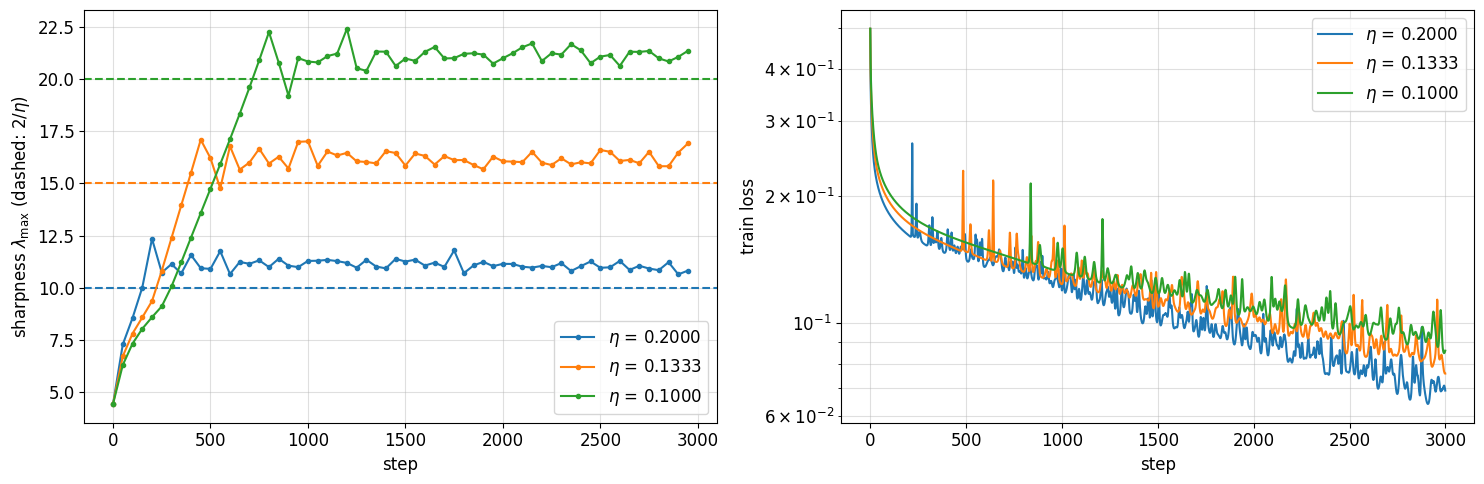

In [71]:
if '7.1' in BONUS_TASKS:
    ETAS = [2 / 10, 2 / 15, 2 / 20]
    eos = {}
    for eta in ETAS:
        model = make_tanh_mlp()
        params = list(model.parameters())
        optimizer = torch.optim.SGD(params, lr=eta)
        run, v = dict(loss=[], steps=[], sharpness=[]), None
        for step in range(EOS_STEPS):
            loss = mse_loss(model)
            if not torch.isfinite(loss):
                print(f'eta = {eta:.4f}: loss разошёлся на шаге {step}')
                break
            run['loss'].append(loss.item())
            if step % 50 == 0:
                lam, v = top_eigenvalue(lambda: mse_loss(model), params, v=v)
                run['steps'].append(step)
                run['sharpness'].append(lam)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        eos[eta] = run
        print(f'eta = {eta:.4f}  2/eta = {2 / eta:.1f}  sharpness: start {run["sharpness"][0]:.1f}, '
              f'max {max(run["sharpness"]):.1f}, last {run["sharpness"][-1]:.1f}  final loss {run["loss"][-1]:.4f}')

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    for eta, run in eos.items():
        line, = ax1.plot(run['steps'], run['sharpness'], 'o-', markersize=3, label=rf'$\eta$ = {eta:.4f}')
        ax1.axhline(2 / eta, color=line.get_color(), linestyle='--')
        ax2.semilogy(run['loss'], color=line.get_color(), label=rf'$\eta$ = {eta:.4f}')
    ax1.set_ylabel(r'sharpness $\lambda_{\max}$ (dashed: $2/\eta$)')
    ax2.set_ylabel('train loss')
    for ax in (ax1, ax2):
        ax.set_xlabel('step')
        ax.grid(True, which='both', alpha=0.4)
        ax.legend()
    plt.tight_layout()
    plt.show()

**Вопрос.** В каких прогонах sharpness приблизилась к $2/\eta$? Если выхода на границу не было, укажите это. Сопоставьте изменения sharpness и loss. Почему локальный критерий для фиксированной положительно определённой квадратичной функции не гарантирует такую же динамику нелинейной сети?

**Ответ.** Во всех трёх прогонах sharpness выросла с 4.4 (progressive sharpening) и вышла на $2/\eta$: при $\eta = 0.2$ — около шага 150–200 (максимум 12.3, дальше держится на 10.7–11.8 при $2/\eta = 10$), при $\eta = 0.133$ — около шага 400 (максимум 17.1, дальше 15.7–17 при $2/\eta = 15$), при $\eta = 0.1$ — около шага 750 (максимум 22.4, дальше ≈ 21 при $2/\eta = 20$); каждый раз она колеблется чуть выше границы, на 5–10%. Пока sharpness ниже $2/\eta$, loss убывает монотонно; после выхода на границу появляются всплески (например, при $\eta = 0.2$ около шага 220, при $\eta = 0.1$ около шагов 830 и 1200), но тренд продолжает убывать до 0.069, 0.076 и 0.086. Критерий $\eta < 2/\lambda_{\max}$ выводится для квадратичной функции с постоянным гессианом, а у сети гессиан меняется вдоль траектории: когда шаг перелетает по верхнему направлению, нелинейные (высшие) члены сами уводят в более плоскую область и снижают sharpness, поэтому вместо расхождения GD держится на границе устойчивости.

## 7.2 Свёртка через FFT со stride, padding и groups (0.5 балла)

Теорема о свёртке: $\mathcal F(x * w) = \mathcal F(x) \cdot \mathcal F(w)$. Детали:

- DFT считает циклическую свёртку — дополняем нулями до $H + k_h - 1$ по высоте и $W + k_w - 1$ по ширине;
- `F.conv2d` — cross-correlation, поэтому ядро переворачивается;
- сумма по входным каналам остаётся суммой в частотной области; с `groups` — только внутри группы;
- padding — `F.pad` входа; stride $s$ — прореживание «valid»-результата $[\,::s,\; ::s\,]$.

Реализуйте `conv2d_fft` (dilation = 1; stride и padding — целые числа) через `torch.fft.rfft2` / `irfft2` и `einsum`.

**Оценивание:** код — 0.4; эксперимент — 0; объяснение — 0.1 балла.

In [72]:
if '7.2' in BONUS_TASKS:
    def conv2d_fft(x, weight, bias=None, stride=1, padding=0, groups=1):
        x = F.pad(x, (padding,) * 4)
        B, C_in, H, W = x.shape
        C_out, _, kh, kw = weight.shape
        size = (H + kh - 1, W + kw - 1)
        Xf = torch.fft.rfft2(x, s=size)
        Wf = torch.fft.rfft2(weight.flip(-2, -1), s=size)
        Xf = Xf.reshape(B, groups, C_in // groups, *Xf.shape[-2:])
        Wf = Wf.reshape(groups, C_out // groups, C_in // groups, *Wf.shape[-2:])
        Yf = torch.einsum('bgcij,gocij->bgoij', Xf, Wf).reshape(B, C_out, *Xf.shape[-2:])
        y = torch.fft.irfft2(Yf, s=size)[..., kh - 1:H, kw - 1:W][..., ::stride, ::stride]
        if bias is not None:
            y = y + bias.view(1, -1, 1, 1)
        return y

In [73]:
if '7.2' in BONUS_TASKS:
    torch.manual_seed(0)
    x = torch.randn(2, 4, 13, 10)
    n_checked = 0
    for k, s, p, g in itertools.product([1, 3, (3, 5)], [1, 2, 3], [0, 1, 2], [1, 2, 4]):
        w, b = torch.randn(8, 4 // g, *pair(k)), torch.randn(8)
        ref = F.conv2d(x, w, b, stride=s, padding=p, groups=g)
        out = conv2d_fft(x, w, b, stride=s, padding=p, groups=g)
        assert out.shape == ref.shape and torch.allclose(out, ref, atol=1e-4), (k, s, p, g)
        n_checked += 1
    n_checked

**Вопрос.** Какую долю посчитанных выходов FFT-свёртка выбрасывает при stride $s$? Когда FFT-свёртка всё равно выгоднее прямой?

**Ответ.** Из «valid»-результата остаётся каждый $s$-й выход по обеим осям, то есть доля $\approx 1/s^2$, а выбрасывается $\approx 1 - 1/s^2$ (75% при $s = 2$, ≈89% при $s = 3$); к этому добавляются границы полной свёртки размера $(H + k_h - 1) \times (W + k_w - 1)$. FFT-свёртка всё равно выгоднее прямой, когда ядро большое (прямая стоит $\propto k_h k_w$ на выход, FFT от $k$ почти не зависит), stride мал и каналов много: преобразования делаются один раз на канал входа и на ядро, а произведение в частотной области стоит $O(C_{\text{in}} C_{\text{out}} H W)$ без множителя $k^2$.

## 7.3 Muon для свёрточных весов (1 балл)

[Muon: An optimizer for hidden layers in neural networks](https://kellerjordan.github.io/posts/muon/), Jordan et al., 2024. Для матричного параметра $W \in \mathbb R^{m \times n}$ с градиентом $G_t$ — так он устроен в `torch.optim.Muon` (momentum через EMA, Nesterov):
$$
B_t = \mu B_{t-1} + (1 - \mu)\, G_t, \qquad U_t = (1 - \mu)\, G_t + \mu B_t, \qquad
W \leftarrow W - \eta \sqrt{\max(1,\, m/n)}\; \mathrm{NS}_5(U_t),
$$
где $\mathrm{NS}_5$ — 5 итераций Ньютона–Шульца, приближающие ортогональный множитель $P Q^\top$ из SVD $U_t = P \Sigma Q^\top$:
$$
X_0 = \frac{U_t}{\|U_t\|_F}, \qquad X_{j+1} = a X_j + b\, (X_j X_j^\top) X_j + c\, (X_j X_j^\top)^2 X_j, \qquad (a, b, c) = (3.4445,\, -4.7750,\, 2.0315)
$$
(если $m > n$, итерации идут для $X^\top$). `torch.optim.Muon` принимает только 2D-параметры, а вес свёртки $(C_{\text{out}}, C_{\text{in}}, k, k)$ — это матрица $C_{\text{out}} \times C_{\text{in}} k^2$ (та же, что в `conv2d_unfold`).

1. Реализуйте `newton_schulz` и `ConvMuon` (без weight decay) для параметров любой размерности $\ge 2$: первая ось — строки, остальные разворачиваются в столбцы. Библиотечный Muon считает итерации в bfloat16, поэтому сравнение с ним — с допуском.
2. Обучите ResNet-20: `ConvMuon` с `MUON_LR` для всех 4D-весов, `MyAdamW` как в `train_cifar` для остального (BN, голова), у обоих cosine schedule, бюджет `EPOCHS`, тот же `set_seed(0)`. Сравните с `history_cifar` из 4.2. Здесь сравниваются два фиксированных training recipe, включая разный weight decay на conv-весах; этот опыт не изолирует влияние одного лишь optimizer и не является общим рейтингом.

**Оценивание:** код — 0.5; эксперимент — 0.3; объяснение — 0.2 балла.

In [74]:
if '7.3' in BONUS_TASKS:
    def newton_schulz(M, steps=5, coeffs=(3.4445, -4.7750, 2.0315)):
        a, b, c = coeffs
        X = M / (M.norm() + 1e-7)
        transposed = X.shape[0] > X.shape[1]
        if transposed:
            X = X.T
        for _ in range(steps):
            A = X @ X.T
            X = a * X + (b * A + c * A @ A) @ X
        return X.T if transposed else X


    class ConvMuon(torch.optim.Optimizer):
        def __init__(self, params, lr=0.02, momentum=0.95):
            super().__init__(params, dict(lr=lr, momentum=momentum))

        @torch.no_grad()
        def step(self):
            for group in self.param_groups:
                mu = group['momentum']
                for p in group['params']:
                    if p.grad is None:
                        continue
                    state = self.state[p]
                    if not state:
                        state['momentum_buffer'] = torch.zeros_like(p)
                    buf = state['momentum_buffer']
                    buf.mul_(mu).add_(p.grad, alpha=1 - mu)
                    U = ((1 - mu) * p.grad + mu * buf).reshape(p.shape[0], -1)
                    m, n = U.shape
                    p.add_(newton_schulz(U).view_as(p), alpha=-group['lr'] * math.sqrt(max(1, m / n)))

In [75]:
if '7.3' in BONUS_TASKS:
    def muon_steps(make_optimizer, shape, steps=5):
        torch.manual_seed(0)
        p = torch.randn(shape, requires_grad=True)
        optimizer = make_optimizer(p)
        gen = torch.Generator().manual_seed(1)
        for _ in range(steps):
            optimizer.zero_grad()
            (p * torch.randn(shape, generator=gen)).sum().backward()
            optimizer.step()
        return p.detach()


    torch.manual_seed(0)
    M = torch.randn(64, 32) * torch.logspace(0, -3, 32)
    assert torch.linalg.svdvals(newton_schulz(M)).max() < 1.3

    for shape in [(48, 20), (20, 48)]:
        start = muon_steps(lambda p: torch.optim.SGD([p], lr=0.0), shape)   # lr = 0: начальная точка
        mine = muon_steps(lambda p: ConvMuon([p], lr=0.02), shape)
        ref = muon_steps(lambda p: torch.optim.Muon([p], lr=0.02, weight_decay=0.0), shape)
        assert ((mine - ref).norm() / (ref - start).norm()) < 0.05, shape

    conv_w = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 8, 3, 3))
    flat = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 72))
    assert torch.allclose(conv_w.view(16, 72), flat, atol=1e-6)

In [76]:
if '7.3' in BONUS_TASKS:
    MUON_LR = 0.02
    set_seed(0)
    resnet20_muon = ResNetCIFAR(20).to(device)
    params = list(resnet20_muon.parameters())
    total_steps = EPOCHS * math.ceil(len(X_train) / 256)
    optimizers = [ConvMuon([p for p in params if p.ndim == 4], lr=MUON_LR),
                  MyAdamW([dict(params=[p for p in params if p.ndim == 2], weight_decay=0.05),
                           dict(params=[p for p in params if p.ndim <= 1], weight_decay=0.0)], lr=LR)]
    schedulers = [torch.optim.lr_scheduler.LambdaLR(o, lambda t: cosine_lr(t, total_steps)) for o in optimizers]
    hist_muon = dict(train_loss=[], test_acc=[])
    start = time.time()
    for epoch in range(EPOCHS):
        resnet20_muon.train()
        total = torch.zeros((), device=device)
        for x, y in iterate_batches(X_train, Y_train, 256, transform=normalize):
            loss = F.cross_entropy(resnet20_muon(x), y)
            for o in optimizers:
                o.zero_grad()
            loss.backward()
            for o, s in zip(optimizers, schedulers):
                o.step()
                s.step()
            total += loss.detach() * len(y)
        hist_muon['train_loss'].append(total.item() / len(X_train))
        hist_muon['test_acc'].append(accuracy(predict_logits(resnet20_muon, X_test, transform=normalize), Y_test))
        print(f'epoch {epoch + 1}/{EPOCHS}  train loss {hist_muon["train_loss"][-1]:.4f}  '
              f'test acc {hist_muon["test_acc"][-1]:.4f}  {time.time() - start:.0f}s')
    hist_adamw = history_cifar
    print(f'{"":<10}{"train loss":>12}{"test acc":>10}')
    for name, hist in [('AdamW', hist_adamw), ('Muon', hist_muon)]:
        print(f'{name:<10}{hist["train_loss"][-1]:>12.4f}{hist["test_acc"][-1]:>10.4f}')

epoch 1/20  train loss 1.1481  test acc 0.6549  18s
epoch 2/20  train loss 0.6678  test acc 0.7270  37s
epoch 3/20  train loss 0.5091  test acc 0.7358  55s
epoch 4/20  train loss 0.4007  test acc 0.8101  74s
epoch 5/20  train loss 0.3160  test acc 0.7963  92s
epoch 6/20  train loss 0.2436  test acc 0.7986  111s
epoch 7/20  train loss 0.1767  test acc 0.8233  130s
epoch 8/20  train loss 0.1263  test acc 0.8345  149s
epoch 9/20  train loss 0.0875  test acc 0.8215  167s
epoch 10/20  train loss 0.0611  test acc 0.8284  186s
epoch 11/20  train loss 0.0397  test acc 0.8272  205s
epoch 12/20  train loss 0.0269  test acc 0.8360  224s
epoch 13/20  train loss 0.0165  test acc 0.8415  243s
epoch 14/20  train loss 0.0096  test acc 0.8415  261s
epoch 15/20  train loss 0.0053  test acc 0.8440  280s
epoch 16/20  train loss 0.0029  test acc 0.8440  299s
epoch 17/20  train loss 0.0017  test acc 0.8452  317s
epoch 18/20  train loss 0.0010  test acc 0.8478  336s
epoch 19/20  train loss 0.0007  test acc 0

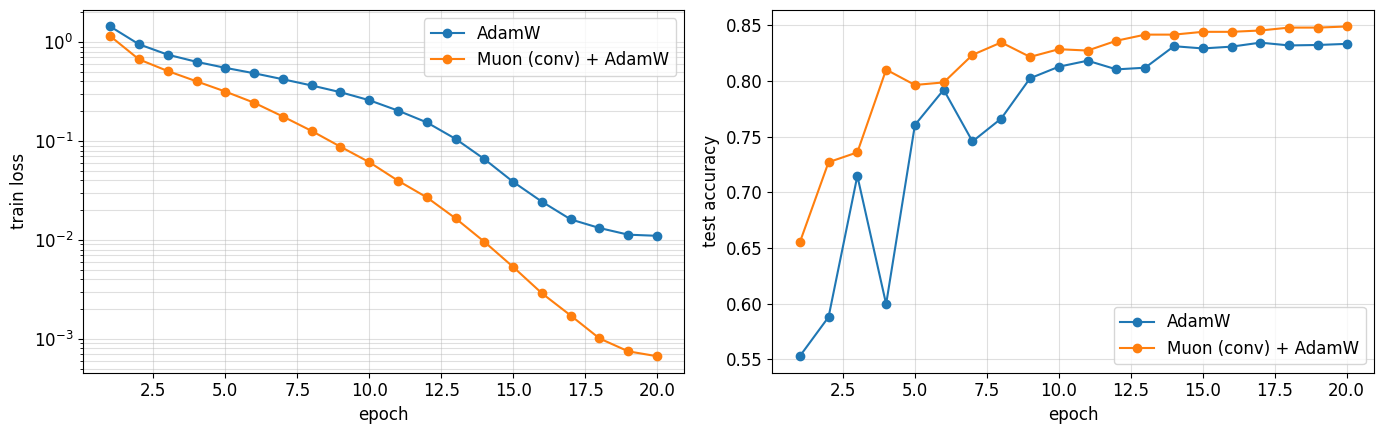

In [77]:
if '7.3' in BONUS_TASKS:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
    for name, hist in [('AdamW', hist_adamw), ('Muon (conv) + AdamW', hist_muon)]:
        epochs_axis = range(1, len(hist['test_acc']) + 1)
        ax1.semilogy(epochs_axis, hist['train_loss'], 'o-', label=name)
        ax2.plot(epochs_axis, hist['test_acc'], 'o-', label=name)
    ax1.set_ylabel('train loss')
    ax2.set_ylabel('test accuracy')
    for ax in (ax1, ax2):
        ax.set_xlabel('epoch')
        ax.grid(True, which='both', alpha=0.4)
        ax.legend()
    plt.tight_layout()
    plt.show()

**Вопрос.** Какой оптимизатор быстрее снижает train loss и какой даёт лучшую test accuracy при том же бюджете? Сколько памяти состояния на параметр у каждого?

**Ответ.** Muon (conv) + AdamW снижает train loss быстрее на всём обучении: 1.148 против 1.436 после 1-й эпохи, 0.061 против 0.258 после 10-й и 0.0007 против 0.0110 в конце. Test accuracy при том же бюджете тоже выше: 0.8488 против 0.8332 (+1.6 п.п.), причём уже с первых эпох (0.810 против 0.600 на 4-й). Это сравнение двух фиксированных рецептов на одном seed (в том числе без weight decay на conv-весах у Muon), а не общий рейтинг оптимизаторов. Память состояния: AdamW хранит 2 числа на параметр ($m$ и $v$), Muon — 1 (momentum buffer), плюс временные матрицы итераций Ньютона–Шульца на шаге.

## 7.4 $L_0$-атака на $L_\infty$-робастную модель (1 балл)

Ограничение — число изменённых пикселей:
$$
\max_{\|\delta\|_0 \le k,\;\; x + \delta \in [0, 1]^d} L\big(f(x + \delta), y\big).
$$
Линеаризация: пиксель $i$ выгоднее всего довести до 0 или до 1, прирост loss
$$
\mathrm{gain}_i = \max\big(g_i (1 - x_i),\; -g_i\, x_i\big), \qquad g = \nabla_x L.
$$
Жадная атака: $k$ раз пересчитать градиент и изменить ещё не тронутый пиксель с максимальным $\mathrm{gain}_i$ — на 1, если $g_i > 0$, иначе на 0.

1. Используйте готовую `greedy_pixel_attack` из семинара 4 ниже; переписывать её не требуется. Баллы — за эксперимент и интерпретацию.
2. Accuracy от $k$ для стандартной модели и PGD-AT на `XF_test[:500]`.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [78]:
if '7.4' in BONUS_TASKS:
    def greedy_pixel_attack(model, x, y, k):
        x_adv = x.detach().clone()
        changed = torch.zeros_like(x_adv, dtype=torch.bool)
        for _ in range(k):
            x_adv.requires_grad_(True)
            with torch.enable_grad():
                grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y, reduction='sum'), x_adv)
            x_adv = x_adv.detach()
            gain = torch.maximum(grad * (1 - x_adv), -grad * x_adv).masked_fill(changed, -float('inf'))
            idx = gain.flatten(1).argmax(dim=1, keepdim=True)
            new_val = (grad.flatten(1).gather(1, idx) > 0).float()
            x_adv = x_adv.flatten(1).scatter(1, idx, new_val).view_as(x)
            changed = changed.flatten(1).scatter(1, idx, True).view_as(x)
        return x_adv

In [79]:
if '7.4' in BONUS_TASKS:
    x, y = XF_test[:500], YF_test[:500]
    x5 = greedy_pixel_attack(model_a, x, y, k=5)
    n_changed = ((x5 - x).flatten(1) != 0).sum(dim=1)
    assert n_changed.max() <= 5 and x5.min() >= 0 and x5.max() <= 1
    assert torch.isin(x5[x5 != x], torch.tensor([0.0, 1.0], device=x.device)).all()
    assert_no_param_grads(model_a)
    print({'clean': attack_accuracy(model_a, x, y), 'L0, k=5': attack_accuracy(model_a, x5, y)})

    ks = [0, 1, 2, 3, 5, 10, 20, 30]
    l0_curves = {name: [attack_accuracy(m, greedy_pixel_attack(m, x, y, k), y) for k in ks]
                 for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
    for name, accs in l0_curves.items():
        print(f'{name:<10}' + ''.join(f'{a:>7.3f}' for a in accs))

{'clean': 0.924, 'L0, k=5': 0.658}
standard    0.924  0.886  0.848  0.786  0.658  0.398  0.130  0.026
PGD-AT      0.854  0.814  0.784  0.768  0.724  0.626  0.424  0.300


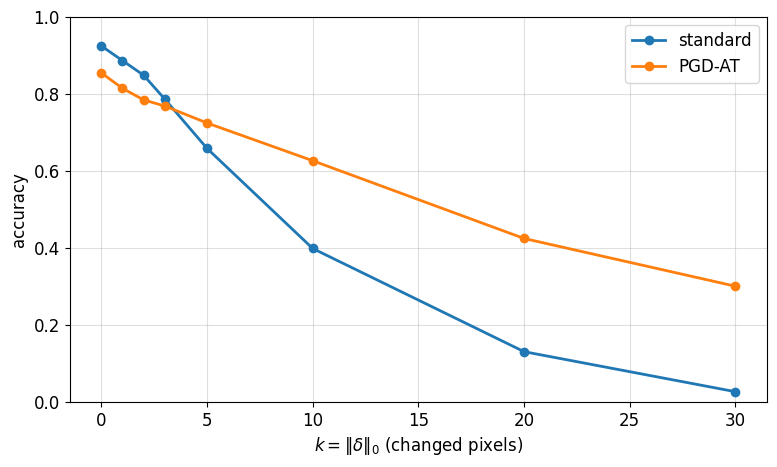

In [80]:
if '7.4' in BONUS_TASKS:
    plt.figure(figsize=(9, 5))
    for name, accs in l0_curves.items():
        plt.plot(ks, accs, 'o-', linewidth=2, label=name)
    plt.xlabel(r'$k = \|\delta\|_0$ (changed pixels)')
    plt.ylabel('accuracy')
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(True, alpha=0.4)
    plt.show()

**Вопрос.** Помогает ли робастность в $L_\infty$ против $L_0$-атаки? Почему $L_\infty$-шар радиуса $\varepsilon$ не защищает от изменения одного пикселя с 0 до 1?

**Ответ.** Помогает слабо. Обычная модель: clean 0.924, при $k = 5$ — 0.658, $k = 10$ — 0.398, $k = 20$ — 0.130, $k = 30$ — 0.026. PGD-AT: 0.854 → 0.724 → 0.626 → 0.424 → 0.300. При малых $k$ PGD-AT хуже в абсолюте из-за более низкой clean accuracy, с $k = 5$ она держится лучше, но 30 изменённых пикселей (3.8% картинки) всё равно снижают её accuracy на 55 п.п. Изменение одного пикселя с 0 до 1 даёт $\|\delta\|_\infty = 1 \gg \varepsilon = 0.1$: такое возмущение лежит далеко вне $L_\infty$-шара, на котором модель обучали, так что робастность к малым плотным возмущениям ничего не говорит о больших разреженных — это разные модели угроз.

## 7.5 Catastrophic overfitting (1 балл)

Включается через `'7.5'` в `BONUS_TASKS`; нужны функции из 6.1 и 6.2. Обучите две дополнительные модели с готовыми FGSM и FGSM-RS при `EPS_CO=0.2`. FGSM-RS начинает из случайной точки, делает один шаг размера $1.25\varepsilon$ и проецируется обратно в допустимое множество.

В работе [Wong et al., 2020](https://arxiv.org/pdf/2001.03994) описано catastrophic overfitting: PGD accuracy резко падает, хотя FGSM accuracy остаётся высокой. Random start может помочь, но ни возникновение эффекта за наш бюджет, ни его устранение не гарантированы.

Код обучения и графика дан; баллы — за диагностику и объяснение. Не меняйте эпохи или радиус только ради получения «нужной картинки». Если добавите контрольный опыт, запишите его настройки отдельно.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [81]:
if '7.5' in BONUS_TASKS:
    EPS_CO = 0.2
    co_history = {}
    for name in ['FGSM', 'FGSM-RS']:
        print(name)
        set_seed(0)
        robust[f'{name}, eps={EPS_CO}'] = SmallCNN()
        co_history[name] = adversarial_train(robust[f'{name}, eps={EPS_CO}'], EPS_CO, TRAIN_ATTACKS[name])

FGSM
epoch 1/5  clean 0.737  fgsm 0.645  pgd 0.037  3s
epoch 2/5  clean 0.603  fgsm 0.935  pgd 0.001  6s
epoch 3/5  clean 0.538  fgsm 0.965  pgd 0.001  9s
epoch 4/5  clean 0.405  fgsm 0.987  pgd 0.001  12s
epoch 5/5  clean 0.402  fgsm 0.993  pgd 0.000  15s
FGSM-RS
epoch 1/5  clean 0.770  fgsm 0.623  pgd 0.375  3s
epoch 2/5  clean 0.792  fgsm 0.652  pgd 0.388  6s
epoch 3/5  clean 0.796  fgsm 0.712  pgd 0.418  9s
epoch 4/5  clean 0.798  fgsm 0.711  pgd 0.430  12s
epoch 5/5  clean 0.811  fgsm 0.743  pgd 0.368  15s


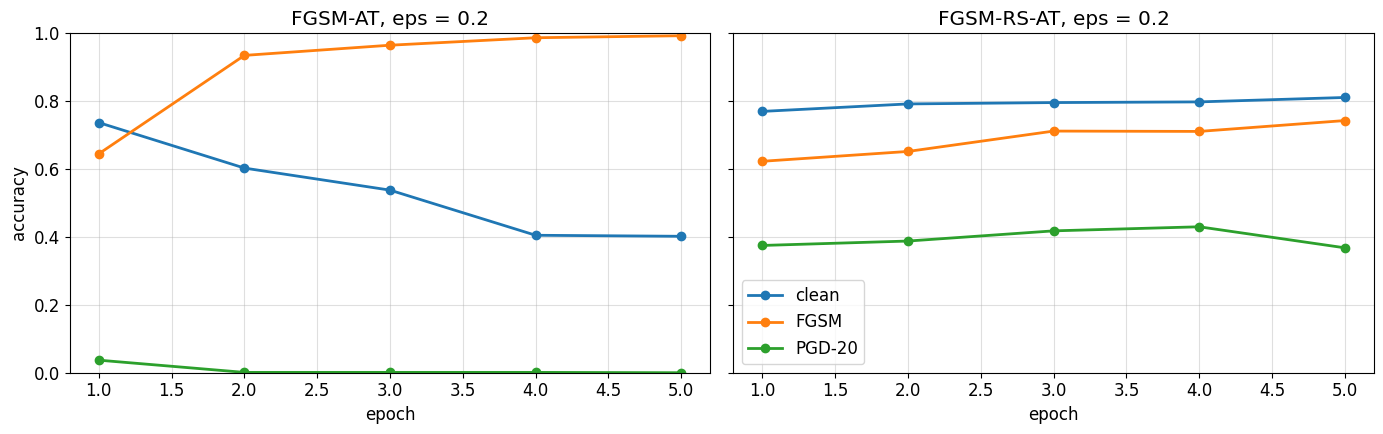

In [82]:
if '7.5' in BONUS_TASKS:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    for ax, (name, hist) in zip(axes, co_history.items()):
        epochs_axis = range(1, len(hist['clean']) + 1)
        for key, label in [('clean', 'clean'), ('fgsm', 'FGSM'), ('pgd', 'PGD-20')]:
            ax.plot(epochs_axis, hist[key], 'o-', linewidth=2, label=label)
        ax.set_title(f'{name}-AT, eps = {EPS_CO}')
        ax.set_xlabel('epoch')
        ax.grid(True, alpha=0.4)
    axes[0].set_ylabel('accuracy')
    axes[0].set_ylim(0, 1)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

In [83]:
if '7.5' in BONUS_TASKS:
    co_checks = {name: sanity_checks(robust[f'{name}, eps={EPS_CO}'], XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_CO)
                 for name in ['FGSM', 'FGSM-RS']}
    print(co_checks)

{'FGSM': {'fgsm': 0.40625, 'pgd20': 0.0, 'pgd100_x5': 0.0, 'eps_1': 0.0}, 'FGSM-RS': {'fgsm': 0.73046875, 'pgd20': 0.35546875, 'pgd100_x5': 0.30859375, 'eps_1': 0.0}}


**Вопрос.** Был ли резкий спад PGD accuracy и на какой эпохе? Изменил ли картину random start? Сопоставьте динамику FGSM/PGD и результаты усиленной атаки. Если catastrophic overfitting не наблюдается, укажите это и предложите одну проверяемую гипотезу о том, от чего он мог бы зависеть.

**Ответ.** Да, у FGSM-AT при $\varepsilon = 0.2$ был резкий спад: PGD-20 accuracy 0.037 уже после 1-й эпохи и 0.001 начиная со 2-й, при этом FGSM accuracy выросла с 0.645 до 0.993, а clean упала с 0.737 до 0.402. FGSM accuracy выше clean — признак catastrophic overfitting: модель научилась делать одношаговую атаку неинформативной (градиент в точке $x$ перестал указывать на худшее направление). Random start изменил картину: у FGSM-RS PGD-20 accuracy 0.375–0.430 по эпохам (0.368 в конце), clean 0.811, FGSM 0.743, коллапса нет; спад с 0.430 до 0.368 на 5-й эпохе на одном seed нельзя отличить от шума или начала эффекта. Усиленная атака это подтверждает (256 объектов, clean-ошибки считаются ошибками): у FGSM-модели FGSM 0.406, PGD-20 0.0, PGD-100 × 5 0.0, у FGSM-RS — 0.730, 0.355 и 0.309. Высокая FGSM accuracy в истории обучения (0.993) объясняется тем, что там clean-ошибки не засчитываются ошибками, а FGSM их «исправляет».